# Tokens, Cost, Batching and Caching: Using LLM APIs Like a Pro

> **Who is this for:** anyone who calls a hosted LLM API (OpenAI, Anthropic, Google Gemini or similar) and wants to understand the bill, make it smaller, and avoid rate-limit errors, without guessing.
>
> **What you will learn:**
> - **tokens for API users**: what a token is, why counts differ per model and language, how images, audio and PDF pages become tokens, and the **hidden tokens** you pay for (system prompt, tools, history, retrieved text, schemas, reasoning)
> - **token types on the bill**: input, output, cached reads, cache writes, reasoning/thinking, batch-discounted and long-context tokens, and how to read the `usage` block of each provider with one **normaliser** function
> - **prompt / context caching** from the user's side: automatic vs explicit breakpoints vs cached-content objects, TTL, write premium vs read discount, and a **day-of-traffic simulator**
> - **Batch APIs** end to end: build a real JSONL file, run it on a local **mock batch server**, poll with backoff, map results by `custom_id`, retry only what failed, and compare the cost with real-time calls
> - **other kinds of "batching"**: client-side concurrency with `asyncio`, many inputs per request, and server-side continuous batching
> - **rate limits**: RPM, TPM, headers, 429 vs 529/503, exponential backoff with jitter, and a **token-bucket limiter** simulation
> - **service tiers** (standard, priority, flex, batch), **output control** (max tokens, stop reasons, continuation, structured outputs, reasoning effort) and **streaming usage**
> - **cost tracking**: per-request cost records, pandas rollups, budgets and alerts, OpenTelemetry GenAI attributes, and a monthly forecast
> - a **ranked token-saving checklist** with a combined before-vs-after demo
>
> **Prerequisites:** [Start Here: How LLMs Work](00_start_here_how_llms_work.ipynb) (tokens, chat roles). Helpful: [Caching in LLM Systems](23_llm_caching_kv_cache_prompt_semantic_cag.ipynb) (how caches work inside) and [AI System Design for LLM Applications](../22_ML_System_Design/09_ai_system_design_for_llm_applications.ipynb) (token budgets, gateways, routing).
>
> **Time needed:** about 2 hours to read and play. The notebook itself runs in well under a minute.
>
> **Runs on:** CPU, no API key, no internet. Every "LLM" and every "server" here is a small Python stand-in. Every price is **made-up and only for illustration**. Provider features change often: everything below is described **as of late 2026 - check the provider's docs** before you rely on a detail.

### The big picture: where the money goes in one API call

A few words first:
- An **API** (application programming interface) is a way for your code to ask another computer to do something. Here: "please run this LLM on my text".
- A **token** is a small piece of text (often part of a word) that the model reads or writes. Providers **charge per token**.
- **Latency** is how long you wait for an answer.

```mermaid
flowchart LR
    A["Your app builds a request:<br/>system prompt + tools + history<br/>+ retrieved docs + question"] --> B{"Prompt cache<br/>(same start as before?)"}
    B -- "hit: cheap cached tokens" --> C[Model reads the input]
    B -- "miss: full-price tokens" --> C
    C --> D["Model may 'think'<br/>(reasoning tokens, billed as output)"]
    D --> E["Model writes the answer<br/>(output tokens, usually the most expensive)"]
    E --> F["Response + usage block<br/>(the token counts you pay for)"]
```

There are four big levers on the bill, and this notebook covers each one:

| Lever | Question it answers | Section |
|---|---|---|
| Fewer tokens | "Do I really need to send all this?" | 1, 8, 11 |
| Cheaper tokens | "Can the same tokens cost less?" (caching, batch, flex, smaller model) | 2, 3, 4, 7 |
| Smarter traffic | "Can I send it without being rate-limited?" | 5, 6 |
| Visibility | "Do I know where the money went?" | 9, 10 |

## 0. Setup

Only the standard library, numpy, pandas and matplotlib. We also define one **made-up price sheet** that every section uses, so the numbers are comparable. Real prices differ per provider and per model and change often.

In [1]:
import json, math, random, re, time, asyncio, tempfile, os, statistics
from collections import Counter, defaultdict, deque
from dataclasses import dataclass, field, asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)

# ALL PRICES ARE MADE-UP, for illustration only. USD per 1 million tokens.
# Real prices: check each provider's pricing page (as of late 2026 they change often).
PRICES = {
    "big-model":   {"input": 3.00, "output": 15.00},   # a large "frontier" model (made-up)
    "small-model": {"input": 0.25, "output": 1.25},    # a small fast model (made-up)
    "embed-model": {"input": 0.02, "output": 0.00},    # an embedding model (made-up)
}
MULT = {                       # multipliers on the input price (typical *shape*, made-up values)
    "cache_read": 0.10,        # cached input read: much cheaper
    "cache_write": 1.25,       # writing to the cache: a small premium (some providers: no premium)
    "batch": 0.50,             # batch / async discount on everything
    "long_ctx_threshold": 200_000,  # above this many input tokens ...
    "long_ctx_mult": 2.0,           # ... some providers charge a higher "long-context" rate
}
def usd(x):
    return f"${x:,.4f}" if x < 1 else f"${x:,.2f}"
print("price sheet loaded (made-up):", PRICES["big-model"], MULT["cache_read"], MULT["batch"])

price sheet loaded (made-up): {'input': 3.0, 'output': 15.0} 0.1 0.5


## 1. Tokens 101 for API users

**What it is:** a **token** is a chunk of text from a fixed list called the **vocabulary**. A **tokenizer** is the program that cuts your text into those chunks. Common words are often one token; rare words are split into several pieces. The model only ever sees token ids, never letters.

**Simple analogy:** a taxi meter. You are not charged per trip, you are charged per distance. With LLMs you are charged per token, both for what you send (input) and for what you get back (output).

**How it works:**
1. Your text (and images, audio, files) is turned into tokens by the provider.
2. The model reads all input tokens, then writes output tokens one by one.
3. The response tells you how many of each you used (the `usage` block, section 2). That is your bill.

**Why the count differs:**
- **Per model:** each model family has its own tokenizer, so the same text can be 1,000 tokens on one model and a noticeably different number on another. Even a new version of the same provider's model can change the tokenizer.
- **Per language:** tokenizers learn their chunks from training text. Languages and scripts that were rare in that text get split into more, smaller pieces, so the same meaning can cost more tokens.
- **Per content type:** code, JSON, numbers, URLs and emojis often split into many small tokens.

Let us see this with a tiny real tokenizer we train ourselves.

### A tiny BPE tokenizer, trained on English only

**BPE** (byte-pair encoding) is the method most LLM tokenizers are based on. It starts from raw bytes and repeatedly glues together the most common neighbouring pair into a new token. We train it on a small English text, so it learns English chunks like `the`, `ing`, ` order`.

In [2]:
def _merge(ids, pair, new_id):
    """Replace every occurrence of `pair` in ids with new_id."""
    out, i = [], 0
    while i < len(ids):
        if i < len(ids) - 1 and (ids[i], ids[i + 1]) == pair:
            out.append(new_id); i += 2
        else:
            out.append(ids[i]); i += 1
    return out

def train_bpe(text, n_merges):
    """Learn n_merges merge rules from text (bytes level, like real LLM tokenizers)."""
    ids, merges = list(text.encode("utf-8")), {}
    for k in range(n_merges):
        pairs = Counter(zip(ids, ids[1:]))
        if not pairs:
            break
        pair = max(pairs, key=pairs.get)           # most frequent neighbouring pair
        merges[pair] = 256 + k                     # new token id
        ids = _merge(ids, pair, 256 + k)
    return merges

def bpe_encode(text, merges):
    ids = list(text.encode("utf-8"))               # start from bytes, so ANY text works
    for pair, new_id in merges.items():            # apply merges in the order learned
        ids = _merge(ids, pair, new_id)
    return ids

ENGLISH_CORPUS = (
    "Thank you for contacting our support team today. Your order has shipped and should arrive within three working days. "
    "Please check the tracking number that we sent to your email address. If your parcel is late, we will refund the shipping cost. "
    "The customer asked about the refund policy and the return window for their order. We are sorry for the delay with your delivery. "
    "Our technical team is working on the problem with the login page and the mobile app. You can reset your password from the settings page. "
    "Please tell us the order number and the email address on your account. We have updated the delivery address for this order. "
    "Your payment was received and the invoice is attached to this email. The item you ordered is back in stock and will ship this week. "
    "Thank you for your patience while we check the status of your request. Please reply to this email if you have any other questions. "
    "The new version of the app fixes the crash on the checkout screen. We will send you an email when the parcel leaves our warehouse. "
)
tok_small = train_bpe(ENGLISH_CORPUS, 30)    # "model A": small vocabulary
tok_big   = train_bpe(ENGLISH_CORPUS, 250)   # "model B": bigger vocabulary
print("model A merges:", len(tok_small), "| model B merges:", len(tok_big))

model A merges: 30 | model B merges: 250


In [3]:
samples = {
    "English":  "Your order has shipped. Please check the tracking number in your email.",
    "Spanish":  "Su pedido ha sido enviado. Revise el numero de seguimiento en su correo.",
    "German":   "Ihre Bestellung wurde versandt. Bitte pruefen Sie die Sendungsnummer.",
    "Hindi":    "आपका ऑर्डर भेज दिया गया है। कृपया ईमेल देखें।",
    "Chinese":  "您的订单已发货。请查看电子邮件中的跟踪号码。",
    "JSON":     '{"order_id": 918273, "status": "shipped", "eta_days": 3}',
}
rows = []
for name, text in samples.items():
    a, b = len(bpe_encode(text, tok_small)), len(bpe_encode(text, tok_big))
    rows.append({"text": name, "chars": len(text), "utf8 bytes": len(text.encode()),
                 "tokens model A": a, "tokens model B": b, "chars per token (B)": round(len(text) / b, 2)})
pd.DataFrame(rows)

,text,chars,utf8 bytes,tokens model A,tokens model B,chars per token (B)
0,English,71,71,44,20,3.55
1,Spanish,72,72,66,57,1.26
2,German,69,69,61,51,1.35
3,Hindi,45,119,119,119,0.38
4,Chinese,22,66,66,66,0.33
5,JSON,56,56,54,43,1.30


**What the table shows (toy tokenizer, but the same effect happens in real ones):**
- The **same text gets a different count on model A and model B**. That is why you must count with the tokenizer of the model you actually call.
- English, the language the tokenizer was trained on, packs the most characters into each token. Text in other scripts falls back to raw **bytes** (Hindi and Chinese characters are 3 bytes each in UTF-8), so it costs many more tokens for a similar message.
- Real provider tokenizers are trained on many languages and do much better than our toy, but the **direction** is common: the more a language or format was seen in training, the cheaper it is.

### Images, audio, PDF pages also become tokens

Multimodal models turn non-text inputs into tokens too, and you pay for them as input tokens:
- **Images** are usually cut into tiles or patches. More pixels means more tokens; many APIs let you choose a lower "detail" or "resolution" setting to pay less.
- **Audio** is usually billed by length (a number of tokens per second, or per-minute pricing).
- **PDFs** are often handled as page images **plus** the extracted text, so one page can cost both.

The exact formula is **provider- and model-specific**. The toy function below only shows the *shape* (cost grows with pixels and duration); its constants are invented.

In [4]:
def toy_image_tokens(width, height, patch=32, max_patches=1500):
    """TOY formula (not any provider's): one token per 32x32 patch, with a cap."""
    return min(max_patches, math.ceil(width / patch) * math.ceil(height / patch))

def toy_audio_tokens(seconds, tokens_per_second=25):      # invented constant
    return int(seconds * tokens_per_second)

for w, h in [(256, 256), (1024, 768), (4000, 3000)]:
    print(f"image {w}x{h:<5} -> {toy_image_tokens(w, h):5d} tokens (toy)")
print(f"audio 60 s       -> {toy_audio_tokens(60):5d} tokens (toy)")
print("A 10-page PDF can mean 10 page images + all the page text: check the provider's PDF docs.")

image 256x256   ->    64 tokens (toy)
image 1024x768   ->   768 tokens (toy)
image 4000x3000  ->  1500 tokens (toy)
audio 60 s       ->  1500 tokens (toy)
A 10-page PDF can mean 10 page images + all the page text: check the provider's PDF docs.


### Rules of thumb, and why you should use the provider's counter

- For **English text**, a common rule of thumb is **about 4 characters per token**, or **about 0.75 words per token**. It is fine for rough budgeting.
- It can be badly wrong for other languages, code, JSON, numbers and images. For anything that matters (billing estimates, fitting into a context window, rate-limit planning), **ask the provider's own counter**:

| Provider | How to count before sending (as of late 2026) |
|---|---|
| OpenAI | the open-source `tiktoken` library for local text counts, or the input-token counting endpoint (`POST /v1/responses/input_tokens`, SDK `client.responses.input_tokens.count(...)`), which also counts tools, images and files |
| Anthropic | the token counting endpoint `POST /v1/messages/count_tokens` (SDK `client.messages.count_tokens(...)`), which takes the same body as a Messages request (system, tools, images, PDFs) |
| Google Gemini | `countTokens` (SDK `client.models.count_tokens(model=..., contents=...)`), plus the `usageMetadata` returned on every response |

The cell below shows the calls. It is **guarded**: it only runs a call if the SDK is installed **and** an API key is set, so here it just prints "skipped".

In [5]:
# Guarded: never crashes, never needs internet unless you have a key set.
def try_provider_counters(text="Your order has shipped."):
    if os.environ.get("OPENAI_API_KEY"):
        try:
            from openai import OpenAI
            r = OpenAI().responses.input_tokens.count(model="YOUR_MODEL", input=text)
            print("OpenAI input tokens:", r.input_tokens)
        except Exception as e:
            print("OpenAI counter failed:", type(e).__name__)
    else:
        print("skipped: OpenAI counter needs the openai package + OPENAI_API_KEY")
    if os.environ.get("ANTHROPIC_API_KEY"):
        try:
            import anthropic
            r = anthropic.Anthropic().messages.count_tokens(
                model="YOUR_MODEL", messages=[{"role": "user", "content": text}])
            print("Anthropic input tokens:", r.input_tokens)
        except Exception as e:
            print("Anthropic counter failed:", type(e).__name__)
    else:
        print("skipped: Anthropic counter needs the anthropic package + ANTHROPIC_API_KEY")
    if os.environ.get("GEMINI_API_KEY"):
        try:
            from google import genai
            r = genai.Client().models.count_tokens(model="YOUR_MODEL", contents=text)
            print("Gemini total tokens:", r.total_tokens)
        except Exception as e:
            print("Gemini counter failed:", type(e).__name__)
    else:
        print("skipped: Gemini counter needs the google-genai package + GEMINI_API_KEY")

try_provider_counters()

skipped: OpenAI counter needs the openai package + OPENAI_API_KEY
skipped: Anthropic counter needs the anthropic package + ANTHROPIC_API_KEY
skipped: Gemini counter needs the google-genai package + GEMINI_API_KEY


For local, offline counting with OpenAI-style tokenizers you would use `tiktoken` (not installed here, and it downloads its vocabulary files the first time):

```python
import tiktoken
enc = tiktoken.get_encoding("o200k_base")      # the encoding name depends on the model family
print(len(enc.encode("Your order has shipped.")))
```

From now on we use a simple **estimator** (about 4 characters per token). It is good enough to compare designs inside this notebook.

In [6]:
def est_tokens(obj):
    """Rough token estimate: ~4 characters per token (English rule of thumb).
    Accepts text or any JSON-able object (dicts/lists are serialised first)."""
    text = obj if isinstance(obj, str) else json.dumps(obj, separators=(",", ":"))
    return max(1, round(len(text) / 4))

print(est_tokens("Your order has shipped. Please check the tracking number in your email."), "tokens (estimate)")

18 tokens (estimate)


### Hidden tokens: what you pay for but never typed

You type one short question, but the request the provider receives is much bigger. Everything in it is billed as input, **on every call**:

| Hidden part | Why it is there | Typical fix |
|---|---|---|
| **System prompt** | instructions, persona, rules | keep it short; cache it (section 3) |
| **Tool / function definitions** | the model must read every tool's name, description and JSON schema | send only the tools this step needs; shorter descriptions |
| **Chat history** | the API is stateless, so you resend the whole conversation each turn | trim old turns, summarise (section 11) |
| **Retrieved context** (RAG) | search results pasted into the prompt | lower top-k, shorter chunks, rerank |
| **JSON schema** for structured output | the schema itself is input | keep schemas small, short field names |
| **Reasoning / thinking tokens** | reasoning models "think" before answering | choose a lower effort / thinking budget (section 8) |
| **Message formatting** | role markers and separators the provider adds | small, but real |

The [AI System Design notebook](../22_ML_System_Design/09_ai_system_design_for_llm_applications.ipynb) (section 7.5) has a full "hidden token leaks" audit. Here we just build one realistic request and ask: **where did my tokens go?**

In [7]:
SYSTEM_PROMPT = ("You are a helpful support assistant for Acme Online Store. " +
                 "Follow the refund policy, be polite, never invent order data, answer in short paragraphs. " * 12)
TOOLS = [
    {"name": f"tool_{n}", "description": f"Use this tool to {d}. " * 3,
     "parameters": {"type": "object", "properties": {"order_id": {"type": "string", "description": "The order id"},
                    "reason": {"type": "string", "description": "Why the customer asks"}}, "required": ["order_id"]}}
    for n, d in [("lookup_order", "look up an order by id"), ("refund", "start a refund"),
                 ("update_address", "change the delivery address"), ("escalate", "hand over to a human agent")]
]
HISTORY = [{"role": r, "content": c} for r, c in [
    ("user", "Hi, my parcel has not arrived yet and it has been a week."),
    ("assistant", "Sorry to hear that! Could you share your order number so I can check?"),
    ("user", "Sure, it is A-55123. I ordered a blue kettle."),
    ("assistant", "Thanks. Order A-55123 shipped 6 days ago and is with the courier. " * 3),
] * 3]
RETRIEVED = ["Refund policy chunk: items can be returned within 30 days of delivery for a full refund. " * 6] * 5
JSON_SCHEMA = {"type": "object", "properties": {"answer": {"type": "string"}, "needs_human": {"type": "boolean"},
               "refund_eligible": {"type": "boolean"}}, "required": ["answer", "needs_human", "refund_eligible"]}
QUESTION = "Can I get a refund if it never arrives?"

PER_MESSAGE_OVERHEAD = 4   # TOY assumption: role markers/separators per message
parts = {
    "system prompt": est_tokens(SYSTEM_PROMPT),
    "tool definitions": est_tokens(TOOLS),
    "chat history": est_tokens(HISTORY) + PER_MESSAGE_OVERHEAD * len(HISTORY),
    "retrieved context": est_tokens(RETRIEVED),
    "JSON schema": est_tokens(JSON_SCHEMA),
    "user question": est_tokens(QUESTION),
}
OUTPUT_PARTS = {"reasoning (hidden, assumed)": 600, "visible answer (assumed)": 120}
breakdown = pd.DataFrame({"tokens": {**parts, **OUTPUT_PARTS}})
breakdown["side"] = ["input"] * len(parts) + ["output"] * len(OUTPUT_PARTS)
breakdown["share of request"] = (breakdown["tokens"] / breakdown["tokens"].sum()).round(3)
p = PRICES["big-model"]
breakdown["cost (made-up $)"] = [t * (p["input"] if s == "input" else p["output"]) / 1e6
                                 for t, s in zip(breakdown["tokens"], breakdown["side"])]
print(f"The question you typed is {parts['user question']} tokens; the request is {sum(parts.values())} input tokens.")
breakdown.round(5)

The question you typed is 10 tokens; the request is 1794 input tokens.


,tokens,side,share of request,cost (made-up $)
system prompt,285,input,0.113,0.00086
tool definitions,361,input,0.144,0.00108
chat history,420,input,0.167,0.00126
retrieved context,672,input,0.267,0.00202
JSON schema,46,input,0.018,0.00014
user question,10,input,0.004,0.00003
"reasoning (hidden, assumed)",600,output,0.239,0.00900
visible answer (assumed),120,output,0.048,0.00180


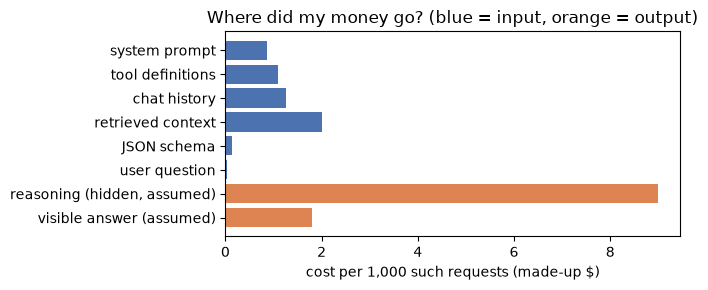

In [8]:
fig, ax = plt.subplots(figsize=(7, 3))
colors = ["#4C72B0" if s == "input" else "#DD8452" for s in breakdown["side"]]
ax.barh(breakdown.index, breakdown["cost (made-up $)"] * 1000, color=colors)
ax.set_xlabel("cost per 1,000 such requests (made-up $)")
ax.set_title("Where did my money go? (blue = input, orange = output)")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

**Reading it:** the user question is a tiny slice. The system prompt, the chat history and the retrieved context dominate the input. On the output side the **hidden reasoning tokens** cost more than the visible answer, because output tokens are priced higher. Most savings in section 11 come from shrinking or caching the big bars, not from shortening the question.

## 2. Token types on the bill

**What it is:** providers do not charge one flat price per token. Different kinds of tokens have different prices. Each response carries a **`usage` block** that tells you how many tokens of each kind you used.

**Simple analogy:** a phone bill with separate lines for calls, texts, roaming and data. You must read each line to know why the total is what it is.

| Token type | What it is | Price shape (typical, check docs) |
|---|---|---|
| **Input** (prompt) tokens | everything you send | base input price |
| **Output** (completion) tokens | everything the model writes | usually **several times** the input price |
| **Cached input (read)** | input that matched a cached prefix | a fraction of the input price |
| **Cache write** | input stored into the cache | on some providers a small premium over input (others: no extra charge) |
| **Reasoning / thinking** | the model's internal "thinking" before the answer | **billed as output**, often not shown to you |
| **Batch-discounted** | tokens sent through a batch API | often around half price |
| **Long-context tier** | requests above a size threshold | some models charge a higher rate for very long prompts |
| **Embedding** tokens | text turned into vectors | input only, usually very cheap |
| **Tool-use / grounding** extras | built-in tools like web search | sometimes a per-call fee on top of tokens |

### Reading the `usage` block: four providers, four shapes

Every provider reports the same ideas with **different field names and different "what includes what" rules**. That is the most common source of wrong cost dashboards. The fixtures below follow the documented field names (as of late 2026); the numbers are made-up but consistent.

In [9]:
# Realistic usage fixtures (made-up numbers, real field names as documented in late 2026).
OPENAI_CHAT = {   # Chat Completions API
    "id": "chatcmpl-123", "object": "chat.completion", "model": "example-model",
    "choices": [{"index": 0, "finish_reason": "stop", "message": {"role": "assistant", "content": "..."}}],
    "usage": {"prompt_tokens": 2450, "completion_tokens": 820, "total_tokens": 3270,
              "prompt_tokens_details": {"cached_tokens": 1920, "audio_tokens": 0},
              "completion_tokens_details": {"reasoning_tokens": 512, "audio_tokens": 0,
                                            "accepted_prediction_tokens": 0, "rejected_prediction_tokens": 0}},
    "service_tier": "default",
}
OPENAI_RESPONSES = {   # Responses API
    "id": "resp_123", "object": "response", "status": "completed", "model": "example-model",
    "usage": {"input_tokens": 2450, "input_tokens_details": {"cached_tokens": 1920},
              "output_tokens": 820, "output_tokens_details": {"reasoning_tokens": 512}, "total_tokens": 3270},
}
ANTHROPIC_MSG = {   # Messages API (a cache HIT)
    "id": "msg_123", "type": "message", "model": "example-model", "stop_reason": "end_turn",
    "usage": {"input_tokens": 530, "cache_creation_input_tokens": 0, "cache_read_input_tokens": 1920,
              "cache_creation": {"ephemeral_5m_input_tokens": 0, "ephemeral_1h_input_tokens": 0},
              "output_tokens": 820, "service_tier": "standard"},
}
ANTHROPIC_MSG_WRITE = {   # same prompt, first call: the cache is WRITTEN
    "id": "msg_122", "type": "message", "model": "example-model", "stop_reason": "end_turn",
    "usage": {"input_tokens": 530, "cache_creation_input_tokens": 1920, "cache_read_input_tokens": 0,
              "cache_creation": {"ephemeral_5m_input_tokens": 1920, "ephemeral_1h_input_tokens": 0},
              "output_tokens": 820, "service_tier": "standard"},
}
GEMINI_RESP = {   # generateContent
    "candidates": [{"finishReason": "STOP", "content": {"role": "model", "parts": [{"text": "..."}]}}],
    "usageMetadata": {"promptTokenCount": 2450, "cachedContentTokenCount": 1920,
                      "candidatesTokenCount": 308, "thoughtsTokenCount": 512, "totalTokenCount": 3270,
                      "promptTokensDetails": [{"modality": "TEXT", "tokenCount": 2450}]},
    "modelVersion": "example-model",
}
print(json.dumps(ANTHROPIC_MSG["usage"], indent=1))

{
 "input_tokens": 530,
 "cache_creation_input_tokens": 0,
 "cache_read_input_tokens": 1920,
 "cache_creation": {
  "ephemeral_5m_input_tokens": 0,
  "ephemeral_1h_input_tokens": 0
 },
 "output_tokens": 820,
 "service_tier": "standard"
}


**The "what includes what" rules (the part people get wrong):**

| | Total input | Cached part | Output | Reasoning part |
|---|---|---|---|---|
| OpenAI Chat Completions | `prompt_tokens` **includes** cached | `prompt_tokens_details.cached_tokens` | `completion_tokens` **includes** reasoning | `completion_tokens_details.reasoning_tokens` |
| OpenAI Responses | `input_tokens` **includes** cached | `input_tokens_details.cached_tokens` | `output_tokens` **includes** reasoning | `output_tokens_details.reasoning_tokens` |
| Anthropic Messages | **sum** of `input_tokens` + `cache_creation_input_tokens` + `cache_read_input_tokens` (`input_tokens` is only the uncached part after the last cache breakpoint) | `cache_read_input_tokens` (writes: `cache_creation_input_tokens`) | `output_tokens` **includes** thinking | may not be reported separately |
| Gemini `generateContent` | `promptTokenCount` **includes** cached content | `cachedContentTokenCount` | `candidatesTokenCount` **excludes** thoughts | `thoughtsTokenCount` (billed as output) |

Newer API versions add fields (for example cache-write counts on some OpenAI models, or new response objects with different names). A normaliser in one place means only one function changes when that happens.

In [10]:
def normalise_usage(provider, resp):
    """Turn any provider's usage block into ONE record with the same meaning everywhere."""
    if provider == "openai_chat":
        u = resp["usage"]; pd_ = u.get("prompt_tokens_details") or {}; cd = u.get("completion_tokens_details") or {}
        cached, write = pd_.get("cached_tokens", 0), pd_.get("cache_write_tokens", 0)
        rec = dict(total_input=u["prompt_tokens"], cache_read=cached, cache_write=write,
                   total_output=u["completion_tokens"], reasoning=cd.get("reasoning_tokens", 0))
    elif provider == "openai_responses":
        u = resp["usage"]; idt = u.get("input_tokens_details") or {}; odt = u.get("output_tokens_details") or {}
        rec = dict(total_input=u["input_tokens"], cache_read=idt.get("cached_tokens", 0),
                   cache_write=idt.get("cache_write_tokens", 0),
                   total_output=u["output_tokens"], reasoning=odt.get("reasoning_tokens", 0))
    elif provider == "anthropic":
        u = resp["usage"]
        read, write = u.get("cache_read_input_tokens", 0) or 0, u.get("cache_creation_input_tokens", 0) or 0
        rec = dict(total_input=u["input_tokens"] + read + write, cache_read=read, cache_write=write,
                   total_output=u["output_tokens"], reasoning=None)   # thinking is inside output_tokens
    elif provider == "gemini":
        u = resp["usageMetadata"]
        thoughts = u.get("thoughtsTokenCount", 0)
        rec = dict(total_input=u["promptTokenCount"] + u.get("toolUsePromptTokenCount", 0),
                   cache_read=u.get("cachedContentTokenCount", 0), cache_write=0,
                   total_output=u.get("candidatesTokenCount", 0) + thoughts, reasoning=thoughts)
    else:
        raise ValueError(provider)
    rec["uncached_input"] = rec["total_input"] - rec["cache_read"] - rec["cache_write"]
    rec["provider"] = provider
    return rec

def cost_of(rec, model="big-model", batch=False):
    """Cost in made-up USD for one normalised record."""
    p = PRICES[model]
    long_ctx = MULT["long_ctx_mult"] if rec["total_input"] > MULT["long_ctx_threshold"] else 1.0
    c = (rec["uncached_input"] * p["input"]
         + rec["cache_read"] * p["input"] * MULT["cache_read"]
         + rec["cache_write"] * p["input"] * MULT["cache_write"]
         + rec["total_output"] * p["output"]) / 1e6 * long_ctx
    return c * (MULT["batch"] if batch else 1.0)

fixtures = [("openai_chat", OPENAI_CHAT), ("openai_responses", OPENAI_RESPONSES),
            ("anthropic", ANTHROPIC_MSG), ("anthropic", ANTHROPIC_MSG_WRITE), ("gemini", GEMINI_RESP)]
recs = []
for prov, resp in fixtures:
    r = normalise_usage(prov, resp); r["cost (made-up $)"] = round(cost_of(r), 6); recs.append(r)
cols = ["provider", "total_input", "uncached_input", "cache_read", "cache_write", "total_output", "reasoning", "cost (made-up $)"]
pd.DataFrame(recs)[cols]

,provider,total_input,uncached_input,cache_read,cache_write,total_output,reasoning,cost (made-up $)
0,openai_chat,2450,530,1920,0,820,512.0,0.014466
1,openai_responses,2450,530,1920,0,820,512.0,0.014466
2,anthropic,2450,530,1920,0,820,NaN,0.014466
3,anthropic,2450,530,0,1920,820,NaN,0.021090
4,gemini,2450,530,1920,0,820,512.0,0.014466


**What to notice:**
- After normalising, the four "hit" responses describe the same request: 2,450 input tokens of which 1,920 were cached, and 820 output tokens. If you had naively added Anthropic's `input_tokens` (530) to your dashboard you would under-count input by about 4x.
- The **cache write** row costs more than the hit row: the first call pays the write premium, later calls get the discount.
- Anthropic's thinking tokens are part of `output_tokens`, so cost is still right, but you cannot see the split (`reasoning = None`).
- Gemini reports thoughts **separately** from the answer, so you must **add** them to get billed output.

Two more bill lines, as quick checks:

In [11]:
# Long-context tier: the same per-token math, but above a threshold the rate changes (made-up rule).
for n_in in [150_000, 250_000]:
    rec = dict(total_input=n_in, uncached_input=n_in, cache_read=0, cache_write=0, total_output=1_000)
    print(f"{n_in:>7,} input tokens -> {usd(cost_of(rec))}  (threshold {MULT['long_ctx_threshold']:,})")

# Embedding a corpus: input-only, cheap per token, but large corpora add up.
corpus_tokens = 50_000 * 500          # 50k documents x ~500 tokens each
print("embedding 50k docs:", usd(corpus_tokens * PRICES["embed-model"]["input"] / 1e6),
      "| same via batch:", usd(corpus_tokens * PRICES["embed-model"]["input"] / 1e6 * MULT["batch"]))

150,000 input tokens -> $0.4650  (threshold 200,000)
250,000 input tokens -> $1.53  (threshold 200,000)
embedding 50k docs: $0.5000 | same via batch: $0.2500


## 3. Prompt / context caching from the API user's view

**What it is:** if the **start (prefix) of your prompt is exactly the same** as in a recent request, the provider can reuse the work it already did on that prefix. You pay a reduced price for those **cached tokens** and usually get the first token back sooner. How it works *inside* (KV cache, prefix trees) is in [Caching in LLM Systems](23_llm_caching_kv_cache_prompt_semantic_cag.ipynb); here we only look at what you control as a user.

**Simple analogy:** a restaurant that keeps a sauce simmering. If the next order needs the same sauce soon, it is ready and cheaper. If nobody orders it for a while, it is thrown away (the **TTL**, time to live, runs out).

**How it works, three styles (as of late 2026, check the docs):**

| | Automatic prefix caching | Explicit breakpoints | Explicit cached-content objects |
|---|---|---|---|
| Typical example | OpenAI (on by default for supported models) | Anthropic `cache_control` markers (plus an automatic top-level option) | Gemini context caching (`client.caches.create`, then pass the cache name) |
| What you do | keep the prefix identical; optionally pass a `prompt_cache_key` to help routing | mark where the cacheable part ends (up to 4 breakpoints) | create a cache object with content and a TTL, then reference it |
| Minimum size | around 1,000+ tokens (model-dependent) | model-dependent minimum (hundreds to a few thousand tokens) | model-dependent minimum |
| TTL | provider-managed; some models offer longer retention options | short default (minutes) with a longer option at a higher write price | you set it; you may also pay for **storage time** |
| Pricing shape | reads discounted; newer models may add a write premium | write premium, large read discount | read discount + storage fee |
| Best for | "it just works" with no code change | precise control over what is cached | a large document reused many times over hours |

Gemini also has **implicit** (automatic) caching on recent models, so both styles exist there too. Always check `cached_tokens`, `cache_read_input_tokens` or `cachedContentTokenCount` in the usage block: **if it stays zero, caching is not happening.**

What the code looks like (shown, not run; needs keys):

```python
# OpenAI: automatic. Keep the long static part first and identical.
resp = client.responses.create(model=MODEL, instructions=LONG_STATIC_INSTRUCTIONS,
                               input=user_question, prompt_cache_key="support-bot-v3")
print(resp.usage.input_tokens_details.cached_tokens)

# Anthropic: explicit breakpoint at the end of the shared part.
resp = client.messages.create(model=MODEL, max_tokens=500,
    system=[{"type": "text", "text": LONG_STATIC_INSTRUCTIONS, "cache_control": {"type": "ephemeral"}}],
    messages=[{"role": "user", "content": user_question}])
print(resp.usage.cache_creation_input_tokens, resp.usage.cache_read_input_tokens)

# Gemini: explicit cached-content object with a TTL (on models that support explicit caching).
from google.genai import types
cache = client.caches.create(model=MODEL, config=types.CreateCachedContentConfig(
            system_instruction=LONG_STATIC_INSTRUCTIONS, contents=[big_document], ttl="3600s"))
resp = client.models.generate_content(model=MODEL, contents=user_question,
            config=types.GenerateContentConfig(cached_content=cache.name))
print(resp.usage_metadata.cached_content_token_count)
```

### Prompt layout: static first, dynamic last

```
 [ tools ][ system prompt ][ long documents / examples ][ chat history ][ new question ]
 |<------------------- stable: same every call ------------>|<-- grows -->|<-- changes -->|
                          cache this part                                   never cached
```

Anything that changes (a timestamp, the user's name, a random id, a re-sorted tool list) placed **early** breaks the cache for everything after it.

**When to use caching:** long, repeated prefixes (big system prompts, tool lists, documents, few-shot examples, agent loops). **When not:** short prompts under the minimum, prefixes that are different on every call, or traffic so sparse that the cache always expires (then you only pay write premiums).

### Simulator: one day of traffic, with and without caching

We simulate 24 hours of a support bot. Traffic is busy in the daytime and almost empty at night. Each request has a 6,000-token static prefix, a 400-token dynamic part and a 300-token answer. We compare:
- **no caching**,
- a **5-minute TTL** (refreshed on every hit),
- a **1-hour TTL** with a higher write premium (made-up 2x),
- a **bad layout** where a timestamp sits at the start, so nothing ever matches.

This is a simplified, single-cache model (real caches can also evict early or live on different machines).

In [12]:
def day_of_traffic(seed=1):
    """Request arrival times in minutes over one day. Busy 9:00-18:00, quiet at night."""
    rng = np.random.default_rng(seed)
    rate = np.array([0.05] * 7 + [0.8, 2.0] + [3.0] * 9 + [1.5, 0.8, 0.4, 0.2, 0.1, 0.05])  # req/min per hour
    times = []
    for h, lam in enumerate(rate):
        n = rng.poisson(lam * 60)
        times += list(np.sort(rng.uniform(h * 60, (h + 1) * 60, n)))
    return np.array(times)

def simulate_cache(times, ttl_min, write_mult, static=6000, dynamic=400, out=300,
                   model="big-model", use_cache=True, always_miss=False):
    """Cost of each request. always_miss=True models a prompt whose start changes every time."""
    p = PRICES[model]; last_use = None; rows = []
    for t in times:
        hit = False
        if not use_cache:
            in_cost = (static + dynamic) * p["input"]
        else:
            hit = (not always_miss) and last_use is not None and (t - last_use) <= ttl_min
            if hit:   # static prefix read from cache at the discounted price
                in_cost = static * p["input"] * MULT["cache_read"] + dynamic * p["input"]
            else:     # miss: the static prefix is (re)written to the cache at the write price
                in_cost = static * p["input"] * write_mult + dynamic * p["input"]
            last_use = t                              # every use refreshes the TTL
        rows.append({"minute": t, "hit": hit, "cost": (in_cost + out * p["output"]) / 1e6})
    return pd.DataFrame(rows)

times = day_of_traffic()
scenarios = {
    "no caching":                  simulate_cache(times, 0, 1.0, use_cache=False),
    "5-min TTL (write 1.25x)":     simulate_cache(times, 5, 1.25),
    "1-hour TTL (write 2x)":       simulate_cache(times, 60, 2.0),
    "bad layout (timestamp first)": simulate_cache(times, 5, 1.25, always_miss=True),
}
summary = pd.DataFrame({name: {"requests": len(df), "hit rate": df["hit"].mean(),
                               "cost per day (made-up $)": df["cost"].sum()} for name, df in scenarios.items()}).T
base = summary.loc["no caching", "cost per day (made-up $)"]
summary["vs no caching"] = (summary["cost per day (made-up $)"] / base - 1).map(lambda x: f"{x:+.0%}")
summary.round(3)

,requests,hit rate,cost per day (made-up $),vs no caching
no caching,1979.0,0.000,46.902,+0%
5-min TTL (write 1.25x),1979.0,0.985,15.464,-67%
1-hour TTL (write 2x),1979.0,0.998,14.945,-68%
bad layout (timestamp first),1979.0,0.000,55.808,+19%


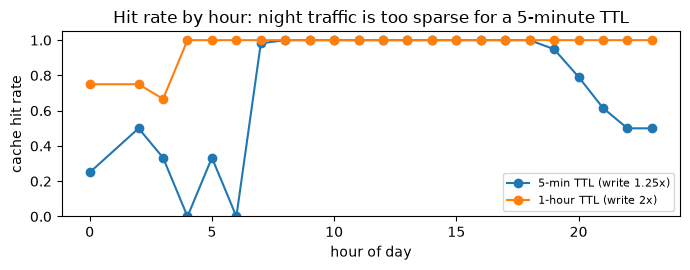

In [13]:
fig, ax = plt.subplots(figsize=(7, 2.8))
for name in ["5-min TTL (write 1.25x)", "1-hour TTL (write 2x)"]:
    df = scenarios[name].assign(hour=lambda d: (d["minute"] // 60).astype(int))
    ax.plot(df.groupby("hour")["hit"].mean(), marker="o", label=name)
ax.set_xlabel("hour of day"); ax.set_ylabel("cache hit rate"); ax.set_ylim(0, 1.05)
ax.set_title("Hit rate by hour: night traffic is too sparse for a 5-minute TTL")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Reading the result:**
- In busy hours almost every request is a hit with either TTL, so the static prefix is paid at the cheap read price.
- At night, requests are often more than 5 minutes apart, so the 5-minute cache keeps expiring and each request pays the **write** premium. The 1-hour TTL keeps hits going at night, but every miss is more expensive. Which one wins depends on your traffic shape; simulate with **your** arrival times.
- The **bad layout** pays the write premium on every request and never reads: it is **more expensive than no caching at all**. With automatic caching you would not pay a premium, but you would still get zero discount.

Silent cache breakers to check for (more in [notebook 23](23_llm_caching_kv_cache_prompt_semantic_cag.ipynb)): timestamps or request ids in the system prompt, unsorted JSON keys, tools that change order, switching models (caches are per model), and changing settings that are part of the cached prefix.

## 4. Batch APIs: half price if you can wait

**What it is:** a **Batch API** lets you submit **many requests at once** (usually as a **JSONL** file, one JSON request per line). The provider processes them **asynchronously** (in the background, not while you wait) within a time window such as **24 hours**, and you download all results later. In return you usually get a large discount (commonly **about 50%**) and separate, higher limits that do not use up your normal real-time rate limits.

**Simple analogy:** a laundry service. Express wash while you wait costs full price. Drop a big bag off in the morning, collect it tomorrow, and you pay half.

**How it works (the same shape at every provider):**

```mermaid
flowchart LR
    A["1. Build requests<br/>(each with a custom_id)"] --> B["2. Upload JSONL file<br/>(or send the list inline)"]
    B --> C["3. Create batch job"]
    C --> D{"4. Poll status<br/>(with backoff)"}
    D -- "still running" --> D
    D -- "done / expired" --> E["5. Download results<br/>+ error file"]
    E --> F["6. Map results by custom_id<br/>(order is NOT guaranteed)"]
    F --> G["7. Retry only the failed items"]
```

**When to use it / when not:**

| Good fit for batch | Bad fit for batch |
|---|---|
| running **evals** over a test set | anything a user is waiting for (chat, autocomplete) |
| **backfills**: classify / tag / summarise last year's tickets | agents that need several dependent steps (each step needs the previous answer) |
| **embedding a whole corpus** for search | tasks needed within seconds or minutes |
| **nightly reports** and digests | tiny jobs where the delay is not worth it |
| **synthetic data** generation | |
| large-scale data cleaning and extraction | |

### The three providers' batch flows (as of late 2026, check the docs)

| | OpenAI Batch API | Anthropic Message Batches | Gemini Batch Mode |
|---|---|---|---|
| Input | JSONL file uploaded with `purpose="batch"`; each line has `custom_id`, `method`, `url`, `body` | list of `{custom_id, params}` sent in the create call | inline list of requests (small jobs) or a JSONL file with `{"key": ..., "request": ...}` per line |
| Endpoints | `/v1/responses`, `/v1/chat/completions`, `/v1/embeddings`, and others; one model per file | Messages API requests | `generateContent` and embeddings |
| Window | `completion_window="24h"` | most finish within an hour; at most 24 hours | target 24 hours |
| Status values | `validating`, `in_progress`, `finalizing`, `completed`, `failed`, `expired`, `cancelling`, `cancelled` | `processing_status`: `in_progress`, `canceling`, `ended`; per item `succeeded` / `errored` / `canceled` / `expired` | `JOB_STATE_PENDING`, `JOB_STATE_RUNNING`, `JOB_STATE_SUCCEEDED`, `JOB_STATE_FAILED`, `JOB_STATE_CANCELLED`, `JOB_STATE_EXPIRED` |
| Results | `output_file_id` (successes) + `error_file_id` (failures); lines may be in any order | stream of results, each with `custom_id` and a result type; any order | output JSONL file (or inline responses); match by `key` |
| Unfinished at deadline | marked `batch_expired` in the error file; finished items are kept and billed | items come back `expired` | job expires; check per-request stats |

Real code, shown only (needs keys and network):

```python
# ---- OpenAI ----
batch_file = client.files.create(file=open("requests.jsonl", "rb"), purpose="batch")
batch = client.batches.create(input_file_id=batch_file.id, endpoint="/v1/chat/completions",
                              completion_window="24h")
batch = client.batches.retrieve(batch.id)          # poll until status is completed / expired / failed
out_lines = client.files.content(batch.output_file_id).text.splitlines()
err_lines = client.files.content(batch.error_file_id).text.splitlines() if batch.error_file_id else []

# ---- Anthropic ----
from anthropic.types.message_create_params import MessageCreateParamsNonStreaming
from anthropic.types.messages.batch_create_params import Request
b = client.messages.batches.create(requests=[
        Request(custom_id=f"t-{i}", params=MessageCreateParamsNonStreaming(
            model=MODEL, max_tokens=10, messages=[{"role": "user", "content": text}]))
        for i, text in enumerate(texts)])
while client.messages.batches.retrieve(b.id).processing_status != "ended":
    time.sleep(60)
for r in client.messages.batches.results(b.id):    # r.custom_id, r.result.type ("succeeded", "errored", ...)
    ...

# ---- Gemini ----
uploaded = client.files.upload(file="requests.jsonl", config=types.UploadFileConfig(mime_type="jsonl"))
job = client.batches.create(model=MODEL, src=uploaded.name)
job = client.batches.get(name=job.name)            # poll job.state until a final JOB_STATE_*
result_bytes = client.files.download(file=job.dest.file_name)
```

Now let us do the whole flow for real, against a local mock server.

### Step 1: build a real JSONL batch file (50 ticket classifications)

**JSONL** ("JSON Lines") is a text file where **each line is one complete JSON object**. It is easy to stream and to append to. We use the OpenAI line format: `custom_id`, `method`, `url`, `body`. The **`custom_id`** is your own unique key; it is how you match each answer back to its input.

In [14]:
LABELS = ["billing", "technical", "shipping", "account"]
TEMPLATES = {
    "billing":   ["I was charged twice for order {n}", "Please refund the extra fee on invoice {n}", "My card was billed the wrong amount"],
    "technical": ["The app crashes when I open settings", "Error 500 on the checkout page", "Login button does nothing on my phone"],
    "shipping":  ["Parcel {n} has not arrived", "Tracking for order {n} has not updated in a week", "Delivery went to the wrong address"],
    "account":   ["How do I change my email address", "Please delete my account", "I cannot reset my password"],
}
rng = random.Random(SEED)
tickets = []
for i in range(50):
    label = LABELS[i % 4]
    text = rng.choice(TEMPLATES[label]).format(n=rng.randint(10000, 99999))
    tickets.append({"id": f"ticket-{i:03d}", "text": text, "true_label": label})

SYSTEM = ("Classify the customer ticket into exactly one label: billing, technical, shipping, account. "
          "Reply with the label only.")
def make_line(t, model="small-model"):
    return {"custom_id": t["id"], "method": "POST", "url": "/v1/chat/completions",
            "body": {"model": model, "max_completion_tokens": 5,
                     "messages": [{"role": "system", "content": SYSTEM}, {"role": "user", "content": t["text"]}]}}

lines = [make_line(t) for t in tickets]
lines[17]["body"].pop("messages")           # simulate a bug: one malformed request (we will catch it later)

WORKDIR = tempfile.mkdtemp(prefix="batch_demo_")   # a temp folder, NOT inside the repo
INPUT_PATH = os.path.join(WORKDIR, "requests.jsonl")
with open(INPUT_PATH, "w") as f:
    for line in lines:
        f.write(json.dumps(line) + "\n")
print("wrote", INPUT_PATH, f"({os.path.getsize(INPUT_PATH):,} bytes)")
print(open(INPUT_PATH).readline().strip())

wrote /tmp/batch_demo_eei6qo9z/requests.jsonl (18,430 bytes)
{"custom_id": "ticket-000", "method": "POST", "url": "/v1/chat/completions", "body": {"model": "small-model", "max_completion_tokens": 5, "messages": [{"role": "system", "content": "Classify the customer ticket into exactly one label: billing, technical, shipping, account. Reply with the label only."}, {"role": "user", "content": "My card was billed the wrong amount"}]}}


In [15]:
def validate_batch_file(path, max_lines=50_000, max_bytes=200 * 1024 * 1024):
    """Cheap local checks BEFORE uploading (limits here mirror OpenAI's documented ones; check the docs)."""
    problems, ids, models = [], Counter(), set()
    with open(path) as f:
        for n, raw in enumerate(f, 1):
            obj = json.loads(raw)
            ids[obj["custom_id"]] += 1
            models.add(obj["body"].get("model"))
            if "messages" not in obj["body"]:
                problems.append(f"line {n} ({obj['custom_id']}): no 'messages' in body")
    if any(c > 1 for c in ids.values()): problems.append("duplicate custom_id values")
    if len(models) > 1: problems.append(f"more than one model in one file: {models}")
    if n > max_lines or os.path.getsize(path) > max_bytes: problems.append("file too big: split it")
    return n, problems

n, problems = validate_batch_file(INPUT_PATH)
print(f"{n} lines checked. Problems found: {problems}")
print("(We deliberately submit anyway, to see how a real batch reports a bad line.)")

50 lines checked. Problems found: ["line 18 (ticket-017): no 'messages' in body"]
(We deliberately submit anyway, to see how a real batch reports a bad line.)


### Step 2: a local mock batch server

This class behaves like a real batch service, but on a **simulated clock** (minutes pass instantly):
- the job goes `validating` -> `in_progress` -> `finalizing` -> `completed`, or `expired` if the window runs out;
- it processes a few requests per simulated minute, **in random order**;
- some requests fail with a temporary server error, a malformed request fails with a 400 error, and anything not done by the deadline is marked `batch_expired`;
- the "model" inside is a **keyword classifier stand-in**, not a real LLM.

We shrink the 24-hour window to a few simulated minutes so that expiry actually happens in the demo.

In [16]:
def fake_classifier(text):
    """Stand-in for an LLM: keyword rules. Returns (label, input_tokens, output_tokens)."""
    t = text.lower()
    rules = [("billing", ["charged", "refund", "invoice", "billed", "fee"]),
             ("shipping", ["parcel", "tracking", "delivery", "arrived"]),
             ("account", ["account", "password", "email"]),
             ("technical", ["crash", "error", "login", "button"])]
    label = next((lab for lab, kws in rules if any(k in t for k in kws)), "technical")
    return label, est_tokens(SYSTEM) + est_tokens(text) + 8, 2

class MockBatchServer:
    def __init__(self, items_per_min=4, server_error_rate=0.06, seed=0):
        self.files, self.batches = {}, {}
        self.items_per_min, self.err_rate, self.rng = items_per_min, server_error_rate, random.Random(seed)

    def upload(self, path):
        fid = f"file-{len(self.files) + 1}"
        self.files[fid] = open(path).read()
        return fid

    def create(self, input_file_id, endpoint, completion_window_min, now):
        reqs = [json.loads(l) for l in self.files[input_file_id].splitlines() if l.strip()]
        self.rng.shuffle(reqs)                               # processing order is not your order
        bid = f"batch-{len(self.batches) + 1}"
        self.batches[bid] = dict(id=bid, status="validating", created=now, deadline=now + completion_window_min,
                                 queue=reqs, out=[], err=[], processed_until=now + 1)  # 1 min validation
        return self._public(bid)

    def _process_one(self, req):
        body = req["body"]
        if "messages" not in body:                          # permanent error: fix it, do not just retry
            return None, {"custom_id": req["custom_id"], "response": {"status_code": 400, "body": {
                "error": {"type": "invalid_request_error", "message": "missing 'messages'"}}}, "error": None}
        if self.rng.random() < self.err_rate:               # temporary error: safe to retry
            return None, {"custom_id": req["custom_id"], "response": {"status_code": 500, "body": {
                "error": {"type": "server_error", "message": "internal error"}}}, "error": None}
        label, n_in, n_out = fake_classifier(body["messages"][-1]["content"])
        return {"custom_id": req["custom_id"], "error": None, "response": {"status_code": 200, "body": {
                "choices": [{"finish_reason": "stop", "message": {"role": "assistant", "content": label}}],
                "usage": {"prompt_tokens": n_in, "completion_tokens": n_out, "total_tokens": n_in + n_out}}}}, None

    def retrieve(self, bid, now):
        b = self.batches[bid]
        while b["status"] in ("validating", "in_progress") and b["processed_until"] <= min(now, b["deadline"]):
            b["status"] = "in_progress"
            for _ in range(self.items_per_min):              # work done during this simulated minute
                if b["queue"]:
                    ok, bad = self._process_one(b["queue"].pop())
                    (b["out"] if ok else b["err"]).append(ok or bad)
            b["processed_until"] += 1
            if not b["queue"]:
                b["status"] = "completed"
        if b["status"] == "in_progress" and now >= b["deadline"]:
            for req in b["queue"]:                           # deadline passed: the rest expires
                b["err"].append({"custom_id": req["custom_id"], "response": None,
                                 "error": {"code": "batch_expired", "message": "not completed in time"}})
            b["queue"], b["status"] = [], "expired"
        return self._public(bid)

    def _public(self, bid):
        b = self.batches[bid]
        done = b["status"] in ("completed", "expired")
        return {"id": bid, "status": b["status"],
                "request_counts": {"total": len(b["queue"]) + len(b["out"]) + len(b["err"]),
                                   "completed": len(b["out"]), "failed": len(b["err"])},
                "output_lines": list(b["out"]) if done else None, "error_lines": list(b["err"]) if done else None}

server = MockBatchServer()
file_id = server.upload(INPUT_PATH)
batch = server.create(file_id, "/v1/chat/completions", completion_window_min=11, now=0.0)
print(batch["id"], batch["status"], batch["request_counts"])

batch-1 validating {'total': 50, 'completed': 0, 'failed': 0}


### Step 3: poll with exponential backoff

**Polling** means asking "are you done yet?" again and again. Asking every second wastes requests (and can hit rate limits). **Exponential backoff** means waiting a little longer after each check (1, 1.5, 2.25 ... minutes, up to a cap), with a bit of random **jitter** so many clients do not all ask at the same moment. Real batch jobs take minutes to hours, so polling every minute or so (or using a webhook, where offered) is typical.

In [17]:
def poll_until_done(server, bid, start=0.0, first_wait=1.0, factor=1.5, max_wait=8.0, rng=random.Random(1)):
    now, wait, log = start, first_wait, []
    while True:
        b = server.retrieve(bid, now)
        log.append({"sim minute": round(now, 1), "status": b["status"], **b["request_counts"]})
        if b["status"] in ("completed", "expired", "failed", "cancelled"):
            return b, pd.DataFrame(log)
        now += wait * rng.uniform(0.8, 1.2)          # sleep (simulated) with jitter
        wait = min(max_wait, wait * factor)

final, poll_log = poll_until_done(server, batch["id"])
print(f"{len(poll_log)} polls. Final status: {final['status']}")
poll_log

6 polls. Final status: expired


,sim minute,status,total,completed,failed
0,0.0,validating,50,0,0
1,0.9,validating,50,0,0
2,2.6,in_progress,50,8,0
3,5.0,in_progress,50,20,0
4,8.1,in_progress,50,31,1
5,13.1,expired,50,41,9


### Step 4: map results by `custom_id`, and sort the failures

Never assume line N of the output belongs to line N of the input. Build a dictionary keyed by `custom_id`. Then sort failures into:
- **retryable**: temporary server errors (5xx) and `batch_expired` items, and
- **needs a fix**: 4xx errors such as a malformed request. Retrying those unchanged just fails again.

In [18]:
def collect(batch_result):
    results, failures = {}, {}
    for line in batch_result["output_lines"]:
        results[line["custom_id"]] = line["response"]["body"]
    for line in batch_result["error_lines"]:
        if line.get("error"):
            failures[line["custom_id"]] = line["error"]["code"]                 # e.g. batch_expired
        else:
            failures[line["custom_id"]] = f"http_{line['response']['status_code']}"
    return results, failures

results, failures = collect(final)
missing = {t["id"] for t in tickets} - results.keys() - failures.keys()
retryable = [cid for cid, why in failures.items() if why == "batch_expired" or why.startswith("http_5")]
needs_fix = [cid for cid, why in failures.items() if cid not in retryable]
print(f"succeeded: {len(results)} | failed: {len(failures)} | missing (should be 0): {len(missing)}")
print("failure reasons:", dict(Counter(failures.values())))
print("needs a fix before retry:", needs_fix)

succeeded: 41 | failed: 9 | missing (should be 0): 0
failure reasons: {'http_400': 1, 'http_500': 2, 'batch_expired': 6}
needs a fix before retry: ['ticket-017']


### Step 5: retry only what failed

We fix the malformed request, then put **only** the failed items into a new, small batch. We never resend the ones that already succeeded (that would pay twice).

In [19]:
by_id = {t["id"]: t for t in tickets}
retry_lines = [make_line(by_id[cid]) for cid in retryable + needs_fix]   # make_line rebuilds a correct body
RETRY_PATH = os.path.join(WORKDIR, "retry.jsonl")
with open(RETRY_PATH, "w") as f:
    f.writelines(json.dumps(l) + "\n" for l in retry_lines)

server.err_rate = 0.0        # pretend the temporary problem has gone away
retry_batch = server.create(server.upload(RETRY_PATH), "/v1/chat/completions", completion_window_min=60, now=30.0)
retry_final, _ = poll_until_done(server, retry_batch["id"], start=30.0)
r2, f2 = collect(retry_final)
results.update(r2)
print(f"retry batch: {len(retry_lines)} items -> {len(r2)} succeeded, {len(f2)} failed")

pred = {cid: body["choices"][0]["message"]["content"] for cid, body in results.items()}
acc = np.mean([pred[t["id"]] == t["true_label"] for t in tickets])
print(f"all {len(pred)}/{len(tickets)} tickets now have an answer; accuracy of the stand-in classifier: {acc:.0%}")

retry batch: 9 items -> 9 succeeded, 0 failed
all 50/50 tickets now have an answer; accuracy of the stand-in classifier: 100%


### Step 6: cost, batch vs real-time

We add up the `usage` of every successful line (including the retry batch) and price it at the real-time rate and at the batch rate. Failed requests are usually not billed for output, but check your provider's rules.

In [20]:
total_in = sum(b["usage"]["prompt_tokens"] for b in results.values())
total_out = sum(b["usage"]["completion_tokens"] for b in results.values())
rec = dict(total_input=total_in, uncached_input=total_in, cache_read=0, cache_write=0, total_output=total_out)
for scale, label in [(1, "these 50 tickets"), (20_000, "a 1,000,000-ticket backfill")]:
    r = {k: v * scale for k, v in rec.items()}
    rt, bt = cost_of(r, "small-model"), cost_of(r, "small-model", batch=True)
    print(f"{label:28s}: real-time {usd(rt):>10}  | batch {usd(bt):>10}  | saved {usd(rt - bt)}")

these 50 tickets            : real-time    $0.0007  | batch    $0.0004  | saved $0.0004
a 1,000,000-ticket backfill : real-time     $28.27  | batch     $14.13  | saved $14.13


### Combining batch and caching discounts

Batch and prompt caching can often **stack** (as of late 2026 several providers say cache hits inside batches are billed at cache rates, check the pricing pages). One catch: batch requests run **in parallel and in any order**, so cache hits inside a batch are **best-effort**. A common trick is to send one request first to warm the cache, and to keep the shared prefix identical in every line. The hit rates below are assumptions, not measurements.

In [21]:
def job_cost(n, shared=3000, own=200, out=5, hit_rate=0.0, batch=False, model="big-model"):
    hits = n * hit_rate
    rec = dict(total_input=n * (shared + own), cache_read=hits * shared,
               cache_write=(n - hits) * shared if hit_rate > 0 else 0, total_output=n * out)
    rec["uncached_input"] = rec["total_input"] - rec["cache_read"] - rec["cache_write"]
    return cost_of(rec, model, batch=batch)

N = 10_000
rows = [("real-time, no cache", job_cost(N)),
        ("real-time + cache (assume 95% hits)", job_cost(N, hit_rate=0.95)),
        ("batch, no cache", job_cost(N, batch=True)),
        ("batch + cache (assume 30% hits)", job_cost(N, hit_rate=0.30, batch=True)),
        ("batch + cache (assume 80% hits)", job_cost(N, hit_rate=0.80, batch=True))]
df = pd.DataFrame(rows, columns=["setup", "cost (made-up $)"])
df["vs real-time"] = (df["cost (made-up $)"] / df.iloc[0, 1]).map(lambda x: f"{x:.0%}")
df.round(2)

,setup,cost (made-up $),vs real-time
0,"real-time, no cache",193.50,100%
1,real-time + cache (assume 95% hits),41.85,22%
2,"batch, no cache",96.75,50%
3,batch + cache (assume 30% hits),88.20,46%
4,batch + cache (assume 80% hits),36.45,19%


## 5. Other ways to "batch"

"Batching" means different things depending on who groups the work. Three more kinds, besides the Batch API:

### 5.1 Client-side concurrency: many real-time calls at once

**What it is:** you send several normal (real-time) requests **at the same time** instead of one after another. You pay the **normal price**, but the whole job finishes much sooner because you are not waiting idle.

**Simple analogy:** one cashier serving a queue vs. opening five tills. Same cost per customer, shorter queue.

**How it works:** with `asyncio`, Python can wait on many network calls at once. `asyncio.gather` starts them all; an `asyncio.Semaphore` (a counter that only lets N tasks in at a time) keeps you from sending 1,000 requests at once and hitting rate limits. The "client" below is a **mock** that just sleeps to imitate network latency.

In [22]:
class MockAsyncLLM:
    """Stand-in for an async SDK client: sleeps 30-60 ms per call, tracks how many calls overlap."""
    def __init__(self):
        self.in_flight, self.max_in_flight, self.calls = 0, 0, 0
    async def complete(self, prompt):
        self.in_flight += 1; self.calls += 1
        self.max_in_flight = max(self.max_in_flight, self.in_flight)
        await asyncio.sleep(random.uniform(0.03, 0.06))       # pretend network + model time
        self.in_flight -= 1
        return fake_classifier(prompt)[0]

async def run_sequential(client, prompts):
    return [await client.complete(p) for p in prompts]

async def run_gather(client, prompts):
    return await asyncio.gather(*(client.complete(p) for p in prompts))

async def run_bounded(client, prompts, limit=5):
    sem = asyncio.Semaphore(limit)
    async def one(p):
        async with sem:                                      # at most `limit` calls in flight
            return await client.complete(p)
    return await asyncio.gather(*(one(p) for p in prompts))

prompts = [t["text"] for t in tickets[:30]]
rows = []
for name, fn in [("sequential", run_sequential), ("gather (no limit)", run_gather), ("gather + semaphore(5)", run_bounded)]:
    client = MockAsyncLLM(); t0 = time.perf_counter()
    out = await fn(client, prompts)                         # top-level await works in Jupyter
    rows.append({"strategy": name, "wall time (s)": round(time.perf_counter() - t0, 2),
                 "max calls at once": client.max_in_flight, "answers": len(out)})
pd.DataFrame(rows)

,strategy,wall time (s),max calls at once,answers
0,sequential,1.31,1,30
1,gather (no limit),0.06,30,30
2,gather + semaphore(5),0.29,5,30


**Reading it:** all three cost the same tokens. Concurrency only cuts **wall-clock time**. Unlimited `gather` is fastest here, but with a real API it is how you get a wall of 429 errors; a semaphore (and the rate limiter in section 6) keeps it safe.

### 5.2 Many inputs in one request

**What it is:** some endpoints accept **a list of inputs per call**. The clearest case is **embeddings**: you can send an array of texts and get an array of vectors back, which cuts request overhead and the number of requests that count toward RPM.

```python
resp = client.embeddings.create(model=EMBED_MODEL, input=["text one", "text two", "text three"])
vectors = [d.embedding for d in resp.data]          # same order as the input list
```

For chat models, you can also **pack several small items into one prompt** ("classify these 20 reviews, answer as a JSON list"). You pay the system prompt **once per pack instead of once per item**, but:
- one bad output (missing item, items out of order, broken JSON) can spoil the **whole pack**;
- items can influence each other ("cross-talk"), so quality can drop as packs get bigger;
- you need stricter parsing and a fallback for failed packs.

The toy below makes that trade-off visible. The stand-in model drops one item from a pack with a probability that grows with pack size (an **invented** error model), and failed packs are re-run one item at a time.

In [23]:
def packed_job_cost(n_items=600, pack=1, sys_tok=400, item_in=40, item_out=6, seed=0):
    rng = random.Random(seed); p = PRICES["small-model"]
    n_calls = in_tok = out_tok = failed_packs = 0
    for start in range(0, n_items, pack):
        k = min(pack, n_items - start)
        n_calls += 1; in_tok += sys_tok + k * item_in; out_tok += k * item_out + 2
        if k > 1 and rng.random() < min(0.6, 0.015 * k):     # INVENTED error model: bigger packs fail more
            failed_packs += 1                                  # -> re-run each item on its own
            n_calls += k; in_tok += k * (sys_tok + item_in); out_tok += k * item_out
    cost = (in_tok * p["input"] + out_tok * p["output"]) / 1e6
    return {"pack size": pack, "API calls": n_calls, "failed packs": failed_packs,
            "input tokens": in_tok, "cost (made-up $)": round(cost, 4)}

pd.DataFrame([packed_job_cost(pack=k) for k in [1, 5, 10, 20, 40]])

,pack size,API calls,failed packs,input tokens,cost (made-up $)
0,1,600,0,264000,0.0720
1,5,140,4,80800,0.0251
2,10,110,5,70000,0.0225
3,20,110,4,71200,0.0230
4,40,375,9,188400,0.0543


**Reading it:** going from 1 to about 10 items per call removes most of the repeated system-prompt cost. Beyond that, failures and retries start eating the savings (in this toy). With real models, **measure quality per pack size on an eval set** before choosing; and note that caching the system prompt (section 3) or the Batch API (section 4) often gets similar savings with less risk.

### 5.3 Server-side continuous batching (not something you control)

Inside the provider, the inference server groups requests from **many users** into one GPU batch and adds or removes them token by token. This is **continuous batching**; it is why hosted APIs are affordable. You do not configure it, but it explains why latency rises when a provider is busy. Details: [LLM Inference Optimization](13_inference_optimization.ipynb).

### Which kind of batching should I pick?

| Kind | Who groups the work | Price effect | Latency | Best for |
|---|---|---|---|---|
| Batch API | the provider, async | often about 50% off | minutes to hours | evals, backfills, corpora, nightly jobs |
| Client concurrency (`asyncio` + semaphore) | your code | none | low (parallel) | many independent real-time calls |
| Many inputs per request (embedding arrays) | your code, one call | fewer requests; same tokens | low | embeddings, moderation lists |
| Packing items into one prompt | your prompt | saves repeated prompt tokens | low | tiny, uniform items; needs careful parsing |
| Continuous batching | the inference server | (makes hosting cheaper) | depends on load | self-hosting with vLLM/TGI etc. |

## 6. Rate limits

**What it is:** providers cap how much you can send per unit of time, per organisation or project, and per model. Go over and you get **HTTP 429 "Too Many Requests"**.

**Simple analogy:** a motorway on-ramp with a traffic light. Cars (requests) and their size (tokens) are both metered. Rushing the light does not get you in faster; it just gets you sent back.

| Limit | Meaning |
|---|---|
| **RPM** | requests per minute |
| **TPM** | tokens per minute; some providers split it into **input TPM (ITPM)** and **output TPM (OTPM)** |
| **RPD / TPD** | requests / tokens per day |
| **Concurrency** | how many requests can be in flight at once (some APIs and tiers) |
| **Batch queue limit** | how many batch tokens or requests can be waiting at once |
| **Spend limit** | a monthly money cap; when hit, requests fail until reset (retrying does not help) |
| **Usage tiers** | your limits grow automatically as your account's paid usage history grows |

Details worth knowing (as of late 2026, check the docs):
- Limits are often enforced as a **token bucket** that refills continuously, so "60 per minute" can behave like "1 per second": short bursts can trip it.
- Some providers count only **uncached** input tokens toward input TPM, so caching also raises your effective throughput.
- Some providers also apply **ramp limits** when your traffic jumps suddenly; ramp up gradually.

### Reading rate-limit headers

Every response tells you how much room you have left:

| Provider | Headers (examples) |
|---|---|
| OpenAI | `x-ratelimit-limit-requests`, `x-ratelimit-remaining-requests`, `x-ratelimit-reset-requests`, the same with `-tokens`, and `retry-after` on some 429/503 responses |
| Anthropic | `anthropic-ratelimit-requests-remaining`, `anthropic-ratelimit-input-tokens-remaining`, `anthropic-ratelimit-output-tokens-remaining`, the `-limit` / `-reset` versions (reset is an RFC 3339 time), and `retry-after` |
| Gemini | errors come back as 429 `RESOURCE_EXHAUSTED`; quotas are shown in the console |

In [24]:
from datetime import datetime, timezone

def parse_duration(s):
    """Parse OpenAI-style reset strings like '12ms', '1s', '6m0s', '1h2m3.5s' into seconds."""
    total = 0.0
    for num, unit in re.findall(r"([\d.]+)(ms|h|m|s)", s):
        total += float(num) * {"ms": 0.001, "s": 1, "m": 60, "h": 3600}[unit]
    return total

OPENAI_HEADERS = {"x-ratelimit-limit-requests": "5000", "x-ratelimit-remaining-requests": "3",
                  "x-ratelimit-reset-requests": "720ms", "x-ratelimit-limit-tokens": "1000000",
                  "x-ratelimit-remaining-tokens": "1200", "x-ratelimit-reset-tokens": "6m0s"}
NOW = datetime(2026, 11, 13, 12, 0, 0, tzinfo=timezone.utc)
ANTHROPIC_HEADERS = {"anthropic-ratelimit-input-tokens-remaining": "0",
                     "anthropic-ratelimit-input-tokens-reset": "2026-11-13T12:00:07Z",
                     "anthropic-ratelimit-requests-remaining": "41", "retry-after": "7"}

def seconds_until_ok(h, need_tokens, now=NOW):
    if "retry-after" in h:                                   # the server told us directly: trust it
        return float(h["retry-after"])
    if "x-ratelimit-remaining-tokens" in h:
        waits = []
        if int(h["x-ratelimit-remaining-requests"]) < 1: waits.append(parse_duration(h["x-ratelimit-reset-requests"]))
        if int(h["x-ratelimit-remaining-tokens"]) < need_tokens: waits.append(parse_duration(h["x-ratelimit-reset-tokens"]))
        return max(waits, default=0.0)
    reset = datetime.fromisoformat(h["anthropic-ratelimit-input-tokens-reset"].replace("Z", "+00:00"))
    return max(0.0, (reset - now).total_seconds())

print("OpenAI-style, need 5,000 tokens  -> wait", seconds_until_ok(OPENAI_HEADERS, 5000), "s (worst case: full reset)")
print("OpenAI-style, need 1,000 tokens  -> wait", seconds_until_ok(OPENAI_HEADERS, 1000), "s")
print("Anthropic-style with retry-after -> wait", seconds_until_ok(ANTHROPIC_HEADERS, 1000), "s")

OpenAI-style, need 5,000 tokens  -> wait 360.0 s (worst case: full reset)
OpenAI-style, need 1,000 tokens  -> wait 0.0 s
Anthropic-style with retry-after -> wait 7.0 s


### 429 vs 529 / 503: "you are too fast" vs "we are too busy"

| Status | Meaning | What to do |
|---|---|---|
| **429** rate limit | **you** went over **your** limit | wait (`retry-after` if given), back off, slow down; check for quota/spend errors that will not clear by waiting |
| **529** overloaded (Anthropic) / **503** unavailable (others) | the **provider** is temporarily overloaded | retry with backoff; consider a fallback model or region |
| **500 / 502 / 504** | a server-side error | retry a few times with backoff |
| **408** timeout | the request took too long | retry; consider streaming or a smaller `max_tokens` |
| **400 / 401 / 403 / 404 / 413 / 422** | your request is wrong (bad body, key, permission, too large) | **do not retry**; fix the request |

### Exponential backoff with jitter, honouring `retry-after`

- **Exponential backoff:** wait 1 s, then 2 s, 4 s, 8 s ... up to a cap.
- **Jitter:** pick a random wait within that range, so thousands of clients do not all retry at the same instant (the "thundering herd").
- **Honour `retry-after`:** if the server says "wait 7 s", never retry earlier.
- **Cap** the number of attempts and the total time. Official SDKs already retry a few times by default; if you add your own loop, turn SDK retries down so you do not retry in two layers.

In [25]:
RETRYABLE = {408, 409, 429, 500, 502, 503, 504, 529}

def should_retry(status, error_code=None):
    if error_code in {"insufficient_quota", "enforced_spend_limit_reached", "billing_hard_limit_reached"}:
        return False                                   # money/quota problems do not clear by waiting
    return status in RETRYABLE

def backoff_delay(attempt, base=1.0, cap=60.0, retry_after=None, rng=random):
    """'Full jitter' backoff: random in [0, min(cap, base*2^attempt)], but never below retry-after."""
    delay = rng.uniform(0, min(cap, base * 2 ** attempt))
    if retry_after is not None:
        delay = max(delay, retry_after) + rng.uniform(0, 0.25)
    return round(delay, 2)

r = random.Random(0)
print("retry 429?", should_retry(429), "| retry 400?", should_retry(400),
      "| retry 429 with spend limit?", should_retry(429, "enforced_spend_limit_reached"))
print("delays without retry-after:", [backoff_delay(a, rng=r) for a in range(6)])
print("delays with retry-after=7 :", [backoff_delay(a, retry_after=7, rng=r) for a in range(3)])

retry 429? True | retry 400? False | retry 429 with spend limit? False
delays without retry-after: [0.84, 1.52, 1.68, 2.07, 8.18, 12.96]
delays with retry-after=7 : [7.08, 7.15, 7.13]


### A client-side token bucket, and a simulation

**What it is:** a **token bucket** is a counter that refills at a steady rate up to a maximum. Each request takes some "tokens" out of it; if there are not enough, you wait. We keep **two buckets**: one for requests (RPM) and one for LLM tokens (TPM), and a request may only go when **both** have room.

**Simple analogy:** a water tank with a tap filling it steadily. You can take a big bucketful at once if the tank is full, but on average you cannot take more than the tap delivers.

The simulation: a backfill job of 300 requests (each 400-1,200 tokens) against a mock server that allows **60 RPM and 40,000 TPM**. We compare three clients:
1. **naive**: on a 429, retry almost immediately;
2. **backoff**: on a 429, wait with jittered exponential backoff, honouring `retry-after`;
3. **limiter**: a local token bucket set a bit **below** the server's limits, so it rarely sees a 429 at all.

In [26]:
class TokenBucket:
    def __init__(self, capacity, refill_per_sec, start_full=True):
        self.capacity, self.rate = capacity, refill_per_sec
        self.level, self.t = (capacity if start_full else 0.0), 0.0
    def _refill(self, now):
        self.level = min(self.capacity, self.level + (now - self.t) * self.rate); self.t = now
    def can_take(self, amount, now):
        self._refill(now); return self.level >= amount
    def take(self, amount, now):
        self._refill(now); self.level -= amount
    def wait_for(self, amount, now):
        self._refill(now); return max(0.0, (amount - self.level) / self.rate)

class DualLimiter:
    """Requests AND tokens must both fit. Used by the server (to reject) and by the client (to wait)."""
    def __init__(self, rpm, tpm):
        self.req, self.tok = TokenBucket(rpm, rpm / 60), TokenBucket(tpm, tpm / 60)
    def try_acquire(self, tokens, now):
        if self.req.can_take(1, now) and self.tok.can_take(tokens, now):
            self.req.take(1, now); self.tok.take(tokens, now); return True, 0.0
        return False, max(self.req.wait_for(1, now), self.tok.wait_for(tokens, now))

In [27]:
def simulate_rate_limits(strategy, n=300, rpm=60, tpm=40_000, safety=0.9, seed=3, horizon=1200, dt=0.1):
    rng = random.Random(seed)
    jobs = deque({"id": i, "tokens": rng.randint(400, 1200), "attempt": 0, "ready_at": 0.0} for i in range(n))
    server = DualLimiter(rpm, tpm)
    client = DualLimiter(rpm * safety, tpm * safety) if strategy == "limiter" else None
    done_times, n429, now = [], 0, 0.0
    while jobs and now < horizon:
        for _ in range(len(jobs)):                      # look at each waiting job once per tick
            j = jobs.popleft()
            if j["ready_at"] > now:
                jobs.append(j); continue
            if client is not None:                      # local limiter: wait instead of sending
                ok, wait = client.try_acquire(j["tokens"], now)
                if not ok:
                    j["ready_at"] = now + wait; jobs.append(j); continue
            ok, retry_after = server.try_acquire(j["tokens"], now)
            if ok:
                done_times.append(now)
            else:
                n429 += 1; j["attempt"] += 1
                if strategy == "naive":
                    j["ready_at"] = now + 0.2                                   # hammer
                else:
                    j["ready_at"] = now + backoff_delay(j["attempt"], base=0.5, cap=30,
                                                        retry_after=retry_after, rng=rng)
                jobs.append(j)
        now += dt
    return {"strategy": strategy, "finished": len(done_times), "429 errors": n429,
            "429s per success": round(n429 / max(1, len(done_times)), 2),
            "total time (s)": round(max(done_times), 1)}, done_times

results_rl, curves = [], {}
for s in ["naive", "backoff", "limiter"]:
    summary_row, times_done = simulate_rate_limits(s)
    results_rl.append(summary_row); curves[s] = times_done
pd.DataFrame(results_rl)

,strategy,finished,429 errors,429s per success,total time (s)
0,naive,300,146976,489.92,305.8
1,backoff,300,3171,10.57,322.8
2,limiter,300,0,0.00,346.4


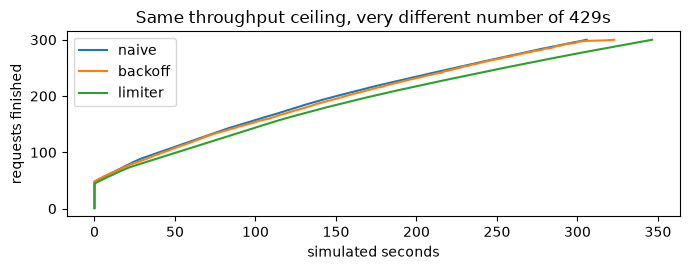

In [28]:
fig, ax = plt.subplots(figsize=(7, 2.8))
for s, ts in curves.items():
    ax.plot(sorted(ts), range(1, len(ts) + 1), label=s)
ax.set_xlabel("simulated seconds"); ax.set_ylabel("requests finished")
ax.set_title("Same throughput ceiling, very different number of 429s")
ax.legend(); plt.tight_layout(); plt.show()

**Reading it:** the server's limits set a **ceiling** on throughput that no client can beat, so all three finish in a similar time (the limiter is a little slower because it deliberately keeps 10% headroom). The difference is the **waste**: the naive client sends thousands of rejected requests (which on a real API also count against your request limit and fill your logs with errors). Backoff cuts that a lot. A **client-side limiter** that stays just under the limits gets the same throughput with almost no 429s. In production you would also update the local buckets from the rate-limit headers, and share one limiter across all workers (for example in Redis), because each process only sees its own traffic.

## 7. Service tiers and processing modes

**What it is:** many providers let you choose **how** your request is processed, trading price against speed and reliability. Names and details differ and change, so this is the general picture **as of late 2026**:

| Mode | Price (relative, typical shape) | Latency | Reliability under load | Typical use |
|---|---|---|---|---|
| **Standard / default** | 1x | normal | normal; may see 429/529 at peaks | most traffic |
| **Priority** | higher than standard | lower and steadier | better (capacity set aside) | user-facing, latency-critical paths with an SLA |
| **Flex / low-cost async** | lower (sometimes batch-like) | slower; may be refused when busy | lower (may get "resource unavailable") | evals, enrichment, jobs that can retry |
| **Batch** | often about 50% off | minutes to 24 h | queued; separate limits | large offline jobs (section 4) |
| **Fast / speed modes** | premium | faster output tokens per second | own limits | interactive, long outputs where speed matters |

How you pick one (examples, check the docs):
- **OpenAI:** a `service_tier` request field (values such as `auto`, `default`, `flex`, `priority`); the response reports which tier actually served it. Flex can return a 429 "resource unavailable" when capacity is short, which you are not charged for.
- **Anthropic:** Priority Tier is a capacity commitment, chosen with a `service_tier` field (`auto` or `standard_only`); `usage.service_tier` reports what was used. Batch is the Message Batches API. Some models offer a premium fast mode.
- **Gemini:** standard, flex and priority tiers exist, and `usageMetadata.serviceTier` reports which one served the request; batch is Batch Mode.

Always log the **served** tier from the response, not just the one you asked for: with `auto`, a request can fall back to a different tier at a different price.

In [29]:
# A tiny chooser: which mode fits a job? (rules of thumb, not a provider API)
def choose_mode(user_waiting, deadline_minutes, can_retry_later, needs_steady_latency):
    if user_waiting and needs_steady_latency:  return "priority"
    if user_waiting:                           return "standard"
    if deadline_minutes >= 24 * 60:            return "batch"
    if can_retry_later:                        return "flex"
    return "standard"

jobs = [("chat reply in a paid product", True, 0, False, True),
        ("chat reply, free tier", True, 0, False, False),
        ("nightly eval over 5,000 cases", False, 24 * 60, True, False),
        ("enrich 2,000 CRM records within the hour", False, 60, True, False),
        ("generate a report the CEO needs in 10 minutes", False, 10, False, False)]
pd.DataFrame([{"job": j[0], "mode": choose_mode(*j[1:])} for j in jobs])

,job,mode
0,chat reply in a paid product,priority
1,"chat reply, free tier",standard
2,"nightly eval over 5,000 cases",batch
3,"enrich 2,000 CRM records within the hour",flex
4,generate a report the CEO needs in 10 minutes,standard


## 8. Output control: paying only for the output you need

Output tokens are usually the most expensive ones, and reasoning tokens count as output. These settings decide how many you pay for.

### 8.1 Output length limits and stop sequences

**What it is:** a **max output tokens** setting is a hard ceiling on what the model may generate. A **stop sequence** is a string that makes the model stop as soon as it writes it.

| | Max output setting | Stop sequences |
|---|---|---|
| OpenAI Chat Completions | `max_completion_tokens` (older `max_tokens` is deprecated); **includes reasoning tokens** | `stop` (up to 4) |
| OpenAI Responses | `max_output_tokens` (includes reasoning) | not offered on every endpoint or model; check the docs |
| Anthropic Messages | `max_tokens` (required) | `stop_sequences` |
| Gemini | `generationConfig.maxOutputTokens` | `generationConfig.stopSequences` (up to 5) |

### 8.2 Why did it stop? `finish_reason` / `stop_reason`

| Meaning | OpenAI Chat | OpenAI Responses | Anthropic | Gemini |
|---|---|---|---|---|
| finished normally | `stop` | `status: "completed"` | `end_turn` | `STOP` |
| **hit the length limit (truncated!)** | `length` | `status: "incomplete"`, `incomplete_details.reason: "max_output_tokens"` | `max_tokens` | `MAX_TOKENS` |
| hit a stop sequence | `stop` | - | `stop_sequence` | `STOP` |
| wants to call a tool | `tool_calls` | output contains function calls | `tool_use` | function call parts |
| blocked / refused | `content_filter` | refusal content | `refusal` | `SAFETY` and others |

**Always check it.** A truncated answer looks normal but is cut off; truncated JSON will not parse.

### A trap with reasoning models: the limit includes the thinking

If a reasoning model needs 300 tokens to think and your limit is 256, you may pay for 256 tokens and get **no visible answer at all**. The stand-in model below shows it.

In [30]:
def fake_reasoning_call(max_output_tokens, reasoning_needed=300, answer_len=120):
    """Stand-in reasoning model: thinks first, then answers, all inside the same output budget."""
    reasoning = min(max_output_tokens, reasoning_needed)
    visible = min(max_output_tokens - reasoning, answer_len)
    finished = reasoning == reasoning_needed and visible == answer_len
    return {"max_output_tokens": max_output_tokens, "reasoning tokens (billed)": reasoning,
            "visible tokens": visible, "finish_reason": "stop" if finished else "length",
            "output cost per 1k calls (made-up $)": round((reasoning + visible) * PRICES["big-model"]["output"] / 1e6 * 1000, 2)}

pd.DataFrame([fake_reasoning_call(m) for m in [256, 400, 600, 1000]])

,max_output_tokens,reasoning tokens (billed),visible tokens,finish_reason,output cost per 1k calls (made-up $)
0,256,256,0,length,3.84
1,400,300,100,length,6.00
2,600,300,120,stop,6.30
3,1000,300,120,stop,6.30


### 8.3 Detecting truncation and continuing

If an answer is cut off (`length` / `max_tokens`), you can ask the model to **continue** by sending the partial answer back. That works, but every continuation **resends the partial text as input**, so a too-small limit costs more in total than a sensible one. Prefer setting the limit right, or asking for shorter output.

In [31]:
LONG_ANSWER = ("Step " + " word" * 9 + ". ") * 60          # a 'true' answer of ~600 tokens (estimated)

def fake_writer(prompt_tokens, already_written, max_tokens):
    """Stand-in model that continues LONG_ANSWER from where it left off."""
    words = LONG_ANSWER.split(" ")
    chunk = words[already_written: already_written + max_tokens]
    finish = "stop" if already_written + len(chunk) >= len(words) else "length"
    return {"text": " ".join(chunk), "n_out": len(chunk), "n_in": prompt_tokens, "finish_reason": finish}

def generate_with_continuation(max_tokens, base_prompt_tokens=500, max_rounds=20):
    written, total_in, total_out, rounds = 0, 0, 0, 0
    while rounds < max_rounds:
        r = fake_writer(base_prompt_tokens + written, written, max_tokens)   # partial answer is re-sent
        total_in += r["n_in"]; total_out += r["n_out"]; written += r["n_out"]; rounds += 1
        if r["finish_reason"] != "length":
            break
    p = PRICES["big-model"]
    return {"max_tokens": max_tokens, "calls": rounds, "input tokens": total_in, "output tokens": total_out,
            "cost (made-up $)": round((total_in * p["input"] + total_out * p["output"]) / 1e6, 5)}

pd.DataFrame([generate_with_continuation(m) for m in [100, 200, 400, 1000]])

,max_tokens,calls,input tokens,output tokens,cost (made-up $)
0,100,7,5600,661,0.02671
1,200,4,3200,661,0.01952
2,400,2,1400,661,0.01412
3,1000,1,500,661,0.01141


### 8.4 Prefilling, structured outputs and short formats

- **Response prefilling** means writing the **first few tokens of the assistant's reply yourself** (for example `{` to force JSON), and letting the model continue. Anthropic historically supported this by ending `messages` with a partial `assistant` turn. **As of late 2026, Anthropic's newest models reject a final assistant prefill with a 400 error**; the recommended replacement is structured outputs or clear instructions. Older models may still accept it, so check the model's docs.
- **Strict structured outputs** make the model follow a JSON schema exactly, so you do not pay for retries of broken JSON. OpenAI: `response_format={"type": "json_schema", "json_schema": {..., "strict": true}}` (Chat) or `text.format` (Responses). Anthropic: `output_config.format` with a JSON schema, or `strict: true` on tool definitions. Gemini: `responseMimeType: "application/json"` with a `responseJsonSchema`. See [Structured Outputs](17_structured_outputs.ipynb).
- Remember the schema itself is **input tokens**, and long field names and pretty-printing are **output tokens**:

In [32]:
verbose = {"classification_result_label": "shipping", "model_confidence_score_between_0_and_1": 0.93,
           "short_human_readable_explanation_of_reasoning": "The customer says the parcel has not arrived."}
compact = {"label": "shipping", "conf": 0.93}
pretty = json.dumps(verbose, indent=4)
for name, obj in [("verbose, pretty-printed", pretty), ("verbose, minified", verbose), ("compact keys, no explanation", compact)]:
    n = est_tokens(obj)
    print(f"{name:30s} ~{n:3d} output tokens -> per 1M calls {usd(n * PRICES['big-model']['output'])} (made-up)")

verbose, pretty-printed        ~ 51 output tokens -> per 1M calls $765.00 (made-up)
verbose, minified              ~ 46 output tokens -> per 1M calls $690.00 (made-up)
compact keys, no explanation   ~  8 output tokens -> per 1M calls $120.00 (made-up)


### 8.5 Reasoning effort and thinking budgets

Reasoning models let you choose **how hard to think**. More thinking can mean better answers on hard problems, but those tokens are **billed as output**, often hidden, and also add latency.

| Provider | Setting (as of late 2026, check docs) |
|---|---|
| OpenAI | `reasoning_effort` (Chat) or `reasoning.effort` (Responses), with levels from `none`/`minimal` up to `high` and above on newer models |
| Anthropic | adaptive thinking with an `effort` level in `output_config` on newer models; older models used a fixed `budget_tokens` |
| Gemini | `thinkingConfig` with `thinkingBudget` (a token number) or `thinkingLevel` |

The reasoning token counts below are **made-up** to show the shape: effort is a **cost dial**. Tune it **per route** on an eval set: simple classification rarely needs high effort.

In [33]:
ASSUMED_REASONING = {"low": 150, "medium": 900, "high": 3500}       # invented averages, NOT measurements
p = PRICES["big-model"]
rows = []
for effort, r_tok in ASSUMED_REASONING.items():
    per_call = (800 * p["input"] + (r_tok + 150) * p["output"]) / 1e6
    rows.append({"effort": effort, "assumed reasoning tokens": r_tok, "visible tokens": 150,
                 "cost per 100k calls (made-up $)": round(per_call * 100_000, 2)})
pd.DataFrame(rows)

,effort,assumed reasoning tokens,visible tokens,cost per 100k calls (made-up $)
0,low,150,150,690.0
1,medium,900,150,1815.0
2,high,3500,150,5715.0


## 9. Streaming and usage

**What it is:** with **streaming**, the API sends the answer in small pieces (chunks, usually as **server-sent events**) as they are generated, instead of one block at the end. It does not change the price, but users see text sooner.

Two numbers to track:
- **TTFT** (time to first token): how long until the first piece arrives. Users feel this most.
- **Output speed**: tokens per second after that.

**Getting usage when streaming** (as of late 2026, check docs):

| Provider | Where usage arrives |
|---|---|
| OpenAI Chat | only if you pass `stream_options={"include_usage": True}`; then a **final chunk** with an empty `choices` list carries `usage` |
| OpenAI Responses | in the final `response.completed` event |
| Anthropic | `message_start` carries input usage; `message_delta` events carry the (cumulative) `output_tokens` |
| Gemini | chunks carry `usageMetadata`; use the last one |

**Cancelling early saves tokens.** If you close the stream once you have what you need (or the user clicks "stop"), generation stops; you are generally billed for the tokens produced up to that point (check your provider's rules).

In [34]:
def fake_stream(answer_tokens=200, ttft_s=0.8, tok_per_s=50, include_usage=True, input_tokens=900):
    """Stand-in for an OpenAI-style stream. Yields (simulated_time, chunk_dict)."""
    t = ttft_s
    text = ["FINAL", "ANSWER:", "shipping", "\n"] + ["(long", "explanation", "nobody", "reads)"] * ((answer_tokens - 4) // 4)
    for i, piece in enumerate(text):
        yield t, {"choices": [{"delta": {"content": piece + " "}, "finish_reason": None}]}
        t += 1 / tok_per_s
    if include_usage:
        yield t, {"choices": [], "usage": {"prompt_tokens": input_tokens, "completion_tokens": len(text)}}

# Read the whole stream
first_t, n_chunks, usage = None, 0, None
for t, chunk in fake_stream():
    if chunk["choices"]:
        first_t = first_t if first_t is not None else t; n_chunks += 1
    else:
        usage = chunk["usage"]
print(f"full stream : TTFT {first_t:.2f}s, {n_chunks} chunks, usage={usage}")

# Cancel as soon as we have the label we need
got, t_cancel = [], None
for t, chunk in fake_stream():
    got.append(chunk["choices"][0]["delta"]["content"])
    if "\n" in got[-1]:
        t_cancel = t; break                      # closing the stream stops generation
saved = usage["completion_tokens"] - len(got)
print(f"cancel early: stopped after {len(got)} tokens at {t_cancel:.2f}s, ~{saved} output tokens not generated")

full stream : TTFT 0.80s, 200 chunks, usage={'prompt_tokens': 900, 'completion_tokens': 200}
cancel early: stopped after 4 tokens at 0.86s, ~196 output tokens not generated


## 10. Cost tracking and observability

**What it is:** recording, for **every** LLM call, who made it, for which feature, with which model, how many tokens of each type, and what it cost. Then adding it up.

**Simple analogy:** an itemised receipt for every purchase, plus a monthly budget app. Without receipts you only see the total and cannot tell what to cut.

**How it works:**
1. After each call, **normalise** the usage (section 2) and compute cost.
2. Attach **tags**: user (or a hash of it), feature, model, prompt version, tier.
3. Store records (a log, a database, or tracing spans).
4. Roll up by day / feature / model / user; set **budgets** and **alerts**.

See also [LLMOps](../15_MLOps/13_llmops.ipynb) (cost tracking tools like Langfuse) and [Cloud Cost Optimization](../18_Cloud/04_cloud_cost_optimization.ipynb).

Below we generate 30 days of synthetic records. On day 20 we inject a realistic bug: someone added the current time to the chat system prompt, so the **chat feature's cache hit rate drops to zero**.

In [35]:
@dataclass
class CostRecord:
    day: int; user: str; feature: str; model: str
    total_input: int; cache_read: int; cache_write: int; total_output: int; batch: bool
    @property
    def uncached_input(self): return self.total_input - self.cache_read - self.cache_write
    def cost(self):
        return cost_of({"total_input": self.total_input, "uncached_input": self.uncached_input,
                        "cache_read": self.cache_read, "cache_write": self.cache_write,
                        "total_output": self.total_output}, self.model, batch=self.batch)

FEATURES = {   # feature: (model, calls/day, input tokens, output tokens, cache hit share, batch?)
    "chat":         ("big-model",   900, 7000, 350, 0.80, False),
    "search_rag":   ("small-model", 1500, 4000, 200, 0.30, False),
    "summarize":    ("big-model",   200, 9000, 600, 0.10, False),
    "nightly_eval": ("big-model",   1000, 2000, 200, 0.50, True),     # 1,000 eval cases via Batch API each night
}
rng_np = np.random.default_rng(7)
records = []
for day in range(1, 31):
    for feat, (model, calls, tin, tout, hit, is_batch) in FEATURES.items():
        n = max(1, int(rng_np.poisson(calls)))
        for _ in range(n):
            ti = int(tin * rng_np.uniform(0.7, 1.3)); to = int(tout * rng_np.uniform(0.7, 1.3))
            h = 0.0 if (feat == "chat" and day >= 20) else hit           # the day-20 bug
            records.append(CostRecord(day, f"user-{rng_np.integers(0, 50):02d}", feat, model,
                                      ti, int(ti * h), 0, to, is_batch))
df_cost = pd.DataFrame([{**asdict(r), "cost": r.cost()} for r in records])
print(f"{len(df_cost):,} call records, total made-up spend {usd(df_cost['cost'].sum())}")
df_cost.groupby("feature").agg(calls=("cost", "size"), input_tokens=("total_input", "sum"),
                                cached=("cache_read", "sum"), cost=("cost", "sum")).sort_values("cost", ascending=False).round(2)

107,852 call records, total made-up spend $794.57


,calls,input_tokens,cached,cost
feature,,,,
chat,27272,190766269,97016527,453.32
summarize,6046,54551806,5452448,203.54
nightly_eval,29857,59780922,29882945,93.93
search_rag,44677,178730759,53599187,43.78


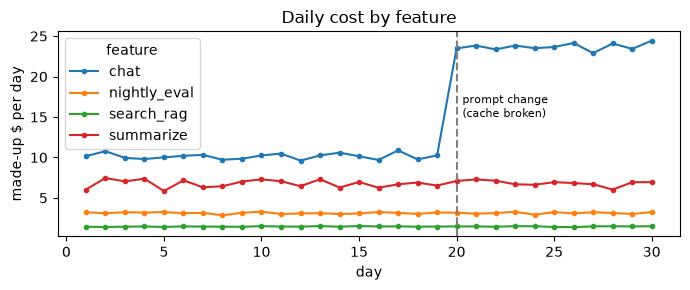

Top 5 users by spend:
user
user-30    16.92
user-43    16.80
user-25    16.70
user-13    16.68
user-24    16.63


In [36]:
daily = df_cost.pivot_table(index="day", columns="feature", values="cost", aggfunc="sum").fillna(0)
fig, ax = plt.subplots(figsize=(7, 3))
daily.plot(ax=ax, marker=".")
ax.axvline(20, color="grey", ls="--"); ax.text(20.3, 15, "prompt change\n(cache broken)", fontsize=8)
ax.set_ylabel("made-up $ per day"); ax.set_title("Daily cost by feature"); plt.tight_layout(); plt.show()

print("Top 5 users by spend:")
print(df_cost.groupby("user")["cost"].sum().nlargest(5).round(2).to_string())

### Budgets and alerts

Two simple, useful alerts:
- **Budget alert:** a feature's daily spend goes over 80% (warning) or 100% (critical) of its budget.
- **Anomaly alert:** today's spend is much higher than the recent normal (here: more than 3 standard deviations above the previous 7 days' mean). This catches bugs like the cache break, even when you are still under budget.

A **cache hit rate** alert per feature is also worth having: a sudden drop is almost always a prompt change.

In [37]:
BUDGET_PER_DAY = {"chat": 15.0, "search_rag": 2.5, "summarize": 10.0, "nightly_eval": 5.0}   # made-up
alerts = []
for feat in daily.columns:
    s = daily[feat]
    for day, spend in s.items():
        b = BUDGET_PER_DAY[feat]
        if spend > b:          alerts.append((day, feat, "CRITICAL over budget", round(spend, 2)))
        elif spend > 0.8 * b:  alerts.append((day, feat, "warning: 80% of budget", round(spend, 2)))
        hist = s.loc[max(1, day - 7): day - 1]
        if len(hist) >= 5 and spend > hist.mean() + 3 * hist.std():
            alerts.append((day, feat, "ANOMALY vs last 7 days", round(spend, 2)))
hit_rate = df_cost[df_cost.feature == "chat"].groupby("day").apply(lambda g: g.cache_read.sum() / g.total_input.sum())
alerts_df = pd.DataFrame(alerts, columns=["day", "feature", "alert", "spend"]).sort_values(["day", "feature"])
print("chat cache hit rate, days 18-21:", hit_rate.loc[18:21].round(2).to_dict())
alerts_df

chat cache hit rate, days 18-21: {18: 0.8, 19: 0.8, 20: 0.0, 21: 0.0}


,day,feature,alert,spend
0,20,chat,CRITICAL over budget,23.49
1,20,chat,ANOMALY vs last 7 days,23.49
2,21,chat,CRITICAL over budget,23.83
3,22,chat,CRITICAL over budget,23.35
4,23,chat,CRITICAL over budget,23.84
5,24,chat,CRITICAL over budget,23.50
6,25,chat,CRITICAL over budget,23.65
7,26,chat,CRITICAL over budget,24.15
8,27,chat,CRITICAL over budget,22.89
9,28,chat,CRITICAL over budget,24.09


### OpenTelemetry GenAI semantic conventions

**OpenTelemetry (OTel)** is an open standard for traces, metrics and logs. Its **GenAI semantic conventions** define standard attribute names for LLM calls, so any observability tool can understand them. As of late 2026 they live in their own repository and are still marked **development** (they can change), and some names have already changed between versions. Names checked against the current registry:

| Attribute | Meaning |
|---|---|
| `gen_ai.operation.name` | e.g. `chat`, `generate_content`, `embeddings` |
| `gen_ai.provider.name` | e.g. `openai`, `anthropic`, `gcp.gemini` (older versions used `gen_ai.system`) |
| `gen_ai.request.model` / `gen_ai.response.model` | model asked for / model that answered |
| `gen_ai.usage.input_tokens` | total input tokens, **including** cached ones |
| `gen_ai.usage.output_tokens` | total output tokens |
| `gen_ai.usage.cache_read.input_tokens` / `gen_ai.usage.cache_write.input_tokens` | cached reads / writes (subsets of input) |
| `gen_ai.usage.reasoning.output_tokens` | reasoning tokens (subset of output) |
| `gen_ai.response.finish_reasons` | list like `["stop"]` |
| `gen_ai.request.max_tokens` | the output limit you set |

Cost is **not** a standard attribute; teams add their own (here `app.cost_usd`). Metric names have changed too (older versions had one `gen_ai.client.token.usage` histogram; the current draft has separate token-usage metrics), so check the version your library implements.

In [38]:
def to_otel_attributes(norm, provider, model, finish_reason, feature, cost):
    """Map a normalised usage record to GenAI semantic-convention span attributes (+ our own app.*)."""
    attrs = {
        "gen_ai.operation.name": "chat",
        "gen_ai.provider.name": provider,
        "gen_ai.request.model": model, "gen_ai.response.model": model,
        "gen_ai.usage.input_tokens": norm["total_input"],              # includes cached tokens
        "gen_ai.usage.output_tokens": norm["total_output"],
        "gen_ai.usage.cache_read.input_tokens": norm["cache_read"],
        "gen_ai.usage.cache_write.input_tokens": norm["cache_write"],
        "gen_ai.response.finish_reasons": [finish_reason],
        "app.feature": feature, "app.cost_usd": round(cost, 6),     # custom, not part of the standard
    }
    if norm.get("reasoning") is not None:
        attrs["gen_ai.usage.reasoning.output_tokens"] = norm["reasoning"]
    return attrs

n = normalise_usage("anthropic", ANTHROPIC_MSG)
print(json.dumps(to_otel_attributes(n, "anthropic", "example-model", "end_turn", "chat", cost_of(n)), indent=1))

{
 "gen_ai.operation.name": "chat",
 "gen_ai.provider.name": "anthropic",
 "gen_ai.request.model": "example-model",
 "gen_ai.response.model": "example-model",
 "gen_ai.usage.input_tokens": 2450,
 "gen_ai.usage.output_tokens": 820,
 "gen_ai.usage.cache_read.input_tokens": 1920,
 "gen_ai.usage.cache_write.input_tokens": 0,
 "gen_ai.response.finish_reasons": [
  "end_turn"
 ],
 "app.feature": "chat",
 "app.cost_usd": 0.014466
}


With the real OpenTelemetry SDK you would set these on a span (shown, not run; many instrumentation libraries do it for you):

```python
from opentelemetry import trace
tracer = trace.get_tracer("my-llm-app")
with tracer.start_as_current_span(f"chat {model}") as span:     # span name: "{operation} {model}"
    resp = client.chat.completions.create(...)
    for k, v in to_otel_attributes(norm, "openai", model, finish, "chat", cost).items():
        span.set_attribute(k, v)
```

Providers also offer **usage and cost reports** for the whole organisation (admin usage/cost APIs and console dashboards). Use those as the source of truth for the invoice, and your own records for the "why".

### A monthly cost forecast calculator

In [39]:
def monthly_forecast(requests_per_day, in_tok, out_tok, model="big-model", cache_hit_share=0.0,
                     batch_share=0.0, monthly_growth=0.0, months=3):
    """Rough forecast. cache_hit_share = share of input tokens read from cache.
    batch_share = share of traffic sent via batch. Prices are the made-up sheet."""
    p = PRICES[model]; out = []
    for m in range(months):
        reqs = requests_per_day * 30 * (1 + monthly_growth) ** m
        in_cost = in_tok * ((1 - cache_hit_share) + cache_hit_share * MULT["cache_read"]) * p["input"]
        per_req = (in_cost + out_tok * p["output"]) / 1e6
        blended = per_req * ((1 - batch_share) + batch_share * MULT["batch"])
        out.append({"month": m + 1, "requests": int(reqs), "cost (made-up $)": round(reqs * blended, 2)})
    return pd.DataFrame(out)

base = monthly_forecast(20_000, 3000, 400, monthly_growth=0.15)
better = monthly_forecast(20_000, 3000, 400, cache_hit_share=0.6, batch_share=0.25, monthly_growth=0.15)
base.assign(**{"with caching + 25% batch": better["cost (made-up $)"]})

,month,requests,cost (made-up $),with caching + 25% batch
0,1,600000,9000.0,5323.50
1,2,690000,10350.0,6122.03
2,3,793499,11902.5,7040.33


## 11. The token-saving checklist (ranked)

Ranked roughly by **savings for effort** for a typical app. Your order may differ: measure your own token profile first (section 1 and 10), and check quality on an eval set after every change.

| # | Technique | What it saves | Effort | Risk to quality |
|---|---|---|---|---|
| 1 | **Prompt caching** (static first, dynamic last) | repeated input | low | none |
| 2 | **Batch API** for anything nobody waits for | ~half of offline spend | low-medium | none (only delay) |
| 3 | **Route easy requests to a small model** | input + output price | medium | measure it |
| 4 | **Trim chat history** / summarise old turns | input | medium | some |
| 5 | **Shorter system prompt** | input on every call | low | some |
| 6 | **Fewer / shorter tool definitions** (send only relevant tools) | input on every call | medium | low |
| 7 | **Tune retrieval top-k** and chunk size | input | low | measure it |
| 8 | **Output limits** and lower reasoning effort | output | low | measure it |
| 9 | **Structured, short outputs** (short keys, no prose) | output | low | low |
| 10 | **Prompt compression** (e.g. LLMLingua-style methods drop low-information tokens) | input | medium | some |
| 11 | **Deduplicate identical requests** (exact-match cache) | whole calls | low | none |
| 12 | **Semantic cache** for similar questions ([notebook 23](23_llm_caching_kv_cache_prompt_semantic_cag.ipynb)) | whole calls | medium | risk of wrong reuse |

Model routing is covered in depth in [AI System Design, section 3.2](../22_ML_System_Design/09_ai_system_design_for_llm_applications.ipynb).

### Before vs after: applying several of them

A support bot with 10,000 conversations per day plus a nightly job. We apply the techniques one at a time and watch the daily cost. All shares and savings are **assumptions** you would replace with measurements.

In [40]:
def daily_cost(cfg):
    """Daily cost of the workload described by cfg (made-up prices)."""
    p_big, p_small = PRICES["big-model"], PRICES["small-model"]
    in_tok = (cfg["system"] + cfg["tools"] + cfg["history"] + cfg["rag_k"] * cfg["chunk"] + cfg["question"])
    out_tok = cfg["reasoning"] + cfg["answer"]
    static = cfg["system"] + cfg["tools"]
    calls = cfg["calls"] * (1 - cfg["dedupe"]) * (1 - cfg["semantic_hit"])
    def per_call(p):
        cached = static * cfg["cache_hit"]
        inp = (in_tok - cached) * p["input"] + cached * p["input"] * MULT["cache_read"]
        return (inp + out_tok * p["output"]) / 1e6
    online = calls * (cfg["small_share"] * per_call(p_small) + (1 - cfg["small_share"]) * per_call(p_big))
    nightly = cfg["nightly_tokens_in"] * p_big["input"] / 1e6 + cfg["nightly_tokens_out"] * p_big["output"] / 1e6
    nightly *= MULT["batch"] if cfg["nightly_batch"] else 1
    return online + nightly

cfg = dict(calls=10_000, system=1500, tools=1200, history=3000, rag_k=8, chunk=300, question=40,
           reasoning=600, answer=250, cache_hit=0.0, small_share=0.0, dedupe=0.0, semantic_hit=0.0,
           nightly_tokens_in=20_000_000, nightly_tokens_out=2_000_000, nightly_batch=False)
steps = [("baseline", {}),
         ("1 prompt caching (assume 85% hits on system+tools)", {"cache_hit": 0.85}),
         ("2 nightly job -> Batch API", {"nightly_batch": True}),
         ("3 route 60% of chats to the small model", {"small_share": 0.6}),
         ("4 trim history to last turns + summary", {"history": 1000}),
         ("5+6 shorter system prompt, only relevant tools", {"system": 800, "tools": 400}),
         ("7 retrieval top-k 8 -> 4", {"rag_k": 4}),
         ("8+9 lower effort, shorter structured answers", {"reasoning": 200, "answer": 150}),
         ("11 dedupe identical requests (assume 5%)", {"dedupe": 0.05}),
         ("12 semantic cache (assume 10% hits)", {"semantic_hit": 0.10})]
rows = []
for name, change in steps:
    cfg.update(change); rows.append({"step": name, "daily cost (made-up $)": round(daily_cost(cfg), 2)})
waterfall = pd.DataFrame(rows)
waterfall["vs baseline"] = (waterfall["daily cost (made-up $)"] / waterfall.iloc[0, 1]).map(lambda x: f"{x:.0%}")
waterfall

,step,daily cost (made-up $),vs baseline
0,baseline,461.70,100%
1,1 prompt caching (assume 85% hits on system+to...,399.74,87%
2,2 nightly job -> Batch API,354.74,77%
3,3 route 60% of chats to the small model,184.38,40%
4,4 trim history to last turns + summary,157.38,34%
5,"5+6 shorter system prompt, only relevant tools",152.62,33%
6,7 retrieval top-k 8 -> 4,136.42,30%
7,"8+9 lower effort, shorter structured answers",102.67,22%
8,11 dedupe identical requests (assume 5%),99.79,22%
9,12 semantic cache (assume 10% hits),94.31,20%


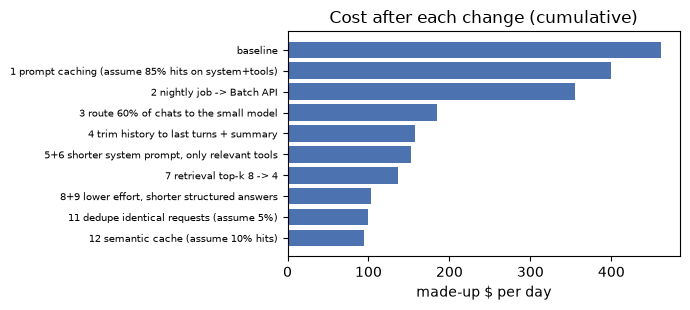

In [41]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(waterfall["step"], waterfall["daily cost (made-up $)"], color="#4C72B0")
ax.invert_yaxis(); ax.set_xlabel("made-up $ per day"); ax.set_title("Cost after each change (cumulative)")
ax.tick_params(axis="y", labelsize=7); plt.tight_layout(); plt.show()

**Reading it:** no single trick does everything. Caching and batch are "free" (no quality risk), routing and trimming are the big structural wins, and the long tail of small changes adds up. The exact percentages here come from our assumptions; **the method** (measure, change one thing, re-measure cost *and* quality) is what transfers to a real system.

## Recap: cheat sheet

| Topic | Remember this |
|---|---|
| Tokens | pieces of text; count differs per model, language and format; ~4 chars/token is only an English rule of thumb; use the provider's counter |
| Hidden tokens | system prompt, tools, history, retrieved text, schemas and reasoning are all billed on every call |
| Bill lines | input, output (pricier), cached read (cheap), cache write (maybe a premium), reasoning (= output), batch (discounted), long-context tiers |
| `usage` block | field names and "what includes what" differ per provider; normalise in one function |
| Prompt caching | identical prefix; static first, dynamic last; check the cached-token field; watch TTL vs traffic gaps |
| Batch API | JSONL + `custom_id`, async within ~24 h, often ~50% off, separate limits; map by `custom_id`; retry only failures |
| Other batching | `asyncio` + semaphore for speed (same price); arrays for embeddings; packing items has a blast radius |
| Rate limits | RPM / TPM (ITPM/OTPM) / daily / concurrency; read the headers; 429 = you, 529/503 = them |
| Retries | exponential backoff + jitter, honour `retry-after`, cap attempts, never retry 4xx bugs or quota errors |
| Limiter | a client-side token bucket for requests **and** tokens gives the same throughput with almost no 429s |
| Service tiers | priority (pay more, steadier), standard, flex (cheaper, may be refused), batch (cheapest, slow) |
| Output control | set max output, check finish/stop reason, reasoning counts toward the limit, use strict structured outputs |
| Streaming | same price, better TTFT; request usage in the stream; cancel early to stop paying |
| Observability | per-call cost records with tags; rollups, budgets, anomaly alerts; OTel `gen_ai.usage.*` attributes |
| Saving tokens | cache, batch, route, trim, shorten, limit, dedupe, then semantic cache; re-check quality each time |

## Interview questions

1. **Why can the same prompt cost a different number of tokens on two models?** Each model family has its own tokenizer (vocabulary), so the same text is split differently; languages, code and JSON vary the most.
2. **A dashboard shows Anthropic input tokens far lower than expected. Why?** `input_tokens` excludes cached reads and writes; total input is `input_tokens + cache_creation_input_tokens + cache_read_input_tokens`.
3. **What are reasoning tokens and how are they billed?** Internal "thinking" tokens produced before the answer; billed as output, often hidden, and they count toward the max output limit.
4. **How do you make prompt caching work well?** Keep a long identical prefix (tools, system, documents) first and dynamic content last; avoid timestamps/ids early; keep tool order stable; verify with the cached-token usage field; match TTL to traffic gaps.
5. **When would you use a Batch API, and when not?** Use it for work nobody waits for (evals, backfills, embeddings of a corpus, nightly jobs, synthetic data) to get a large discount and separate limits; not for user-facing or multi-step dependent work.
6. **Batch results came back in a different order and some failed. What do you do?** Map by `custom_id`; split failures into retryable (5xx, expired) and needs-fix (4xx); resubmit only those; never resend successes.
7. **What is the difference between a 429 and a 529/503?** 429 means you exceeded your rate limit; 529 (Anthropic) / 503 means the provider is overloaded. Both are retryable with backoff, but 429 also means you should slow down.
8. **Explain exponential backoff with jitter.** Wait times grow exponentially per attempt up to a cap, with randomness so clients do not retry in sync; always wait at least `retry-after` when given.
9. **How does a client-side token bucket help if the server already enforces limits?** It spaces requests so you stay under the limit, avoiding wasted rejected calls, error noise and penalties, with the same throughput.
10. **Name five ways to cut an LLM bill without changing the model.** Prompt caching, batch for offline work, trimming history, fewer tool definitions, lower retrieval top-k, output limits and short structured outputs, dedupe, semantic cache.

## Further reading

Provider docs (check them, they change often; URLs as of late 2026):
- OpenAI: Batch API guide, https://developers.openai.com/api/docs/guides/batch ; Prompt caching, https://developers.openai.com/api/docs/guides/prompt-caching ; Rate limits, https://developers.openai.com/api/docs/guides/rate-limits ; Flex processing, https://developers.openai.com/api/docs/guides/flex-processing ; Token counting, https://developers.openai.com/api/docs/guides/token-counting
- Anthropic: Batch processing, https://platform.claude.com/docs/en/build-with-claude/batch-processing ; Prompt caching, https://platform.claude.com/docs/en/build-with-claude/prompt-caching ; Rate limits, https://platform.claude.com/docs/en/api/rate-limits ; Token counting, https://platform.claude.com/docs/en/build-with-claude/token-counting ; Pricing, https://platform.claude.com/docs/en/about-claude/pricing
- Google Gemini: Batch mode, https://ai.google.dev/gemini-api/docs/batch-mode ; Context caching, https://ai.google.dev/gemini-api/docs/caching ; API reference for `generateContent` and `usageMetadata`, https://ai.google.dev/api/generate-content
- OpenTelemetry GenAI semantic conventions, https://github.com/open-telemetry/semantic-conventions-genai

Papers and articles:
- Jiang et al., *LLMLingua: Compressing Prompts for Accelerated Inference of Large Language Models* (2023), arXiv:2310.05736.
- Yu et al., *Orca: A Distributed Serving System for Transformer-Based Generative Models* (OSDI 2022), the origin of continuous ("iteration-level") batching.
- Sennrich, Haddow and Birch, *Neural Machine Translation of Rare Words with Subword Units* (2016), the BPE tokenization paper, arXiv:1508.07909.
- Marc Brooker, *Exponential Backoff And Jitter*, AWS Architecture Blog (2015).

Related notebooks in this repo: [Caching in LLM Systems](23_llm_caching_kv_cache_prompt_semantic_cag.ipynb), [AI System Design for LLM Applications](../22_ML_System_Design/09_ai_system_design_for_llm_applications.ipynb), [LLM Inference Optimization](13_inference_optimization.ipynb), [Structured Outputs](17_structured_outputs.ipynb), [Reasoning Models](18_reasoning_models.ipynb), [LLMOps](../15_MLOps/13_llmops.ipynb), [Cloud Cost Optimization](../18_Cloud/04_cloud_cost_optimization.ipynb).